In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pylabdd as dd
from matplotlib.gridspec import GridSpec
from scipy.signal import savgol_filter

# store plastic slip rates and temperatures
psr_list = np.zeros((3,4))
temp_list = np.zeros(3)
maxout = 1000

# plot function for stress and pile-up dislocations
def plot_stress_bfield(npt = 300, file=None, cutoff=100.):
    xpts = np.linspace(0.0, dsl.lx, npt)
    ypts = np.linspace(0.0, dsl.ly, npt)
    XP, YP = np.meshgrid(xpts, ypts)
    s12 = np.zeros((npt, npt), dtype=np.float64)
    for i in range(dsl.Ntot):
        s12 += dsl.bx[i] * dsl.sig_xy(XP - dsl.xpos[i], YP - dsl.ypos[i])
        s12 -= dsl.by[i] * dsl.sig_xy(YP - dsl.ypos[i], XP - dsl.xpos[i])
    extent = (0.0, dsl.lx, 0.0, dsl.ly)
    
    #fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 12), gridspec_kw={"height_ratios": [4, 1]}, sharex=True)
    fig = plt.figure(figsize=(12, 9))
    gs = GridSpec(2, 1, height_ratios=[4, 1], hspace=0.0)
    # -----------------------------
    # upper plot: stress field and dislocations
    # -----------------------------
    ax1 = fig.add_subplot(gs[0])
    #ax1.xaxis.set_label_position('top')
    #ax1.set_xlabel(r"x ($\mu$m)")
    ax1.xaxis.tick_top()
    plt.setp(ax1.get_xticklabels(), visible=False)
    ax1.set_ylabel(r"y ($\mu$m)")
    im = ax1.imshow(s12, origin="lower", extent=extent,
        vmin=-cutoff, vmax=cutoff, cmap=plt.cm.RdBu, aspect="equal")
    ax1.scatter(dsl.xpos[:npu], dsl.ypos[:npu], s=10, c="yellow", marker="o")
    cbar = fig.colorbar(im, ax=ax1, pad=0.08)
    #cbar.set_label(r"$\sigma_{12}$ (MPa)")
    cbar.ax.set_title(r"$\sigma_{12}$ (MPa)")
    
    # -----------------------------
    # Lower Plot: b-field
    # -----------------------------
    ax2 = fig.add_subplot(gs[1], sharex=ax1)
    ax2.plot(dsl.xpos[npu:], dsl.by[npu:], lw=2)  #color=plt.cm.viridis(0)
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_ylim(0., dsl.by[npu:].max())
    ax2.invert_yaxis()
    pos1 = ax1.get_position()
    pos2 = ax2.get_position()
    ax2.set_position([
        pos1.x0,
        pos2.y0,
        pos1.width,
        pos2.height
    ])
    ax2.set_ylabel(r"$b_y \, / \, B$")
    ax2.set_xlabel(r"x ($\mu$m)")
    ax2.yaxis.set_label_position('right')
    ax2.yaxis.tick_right()
    if file is not None:
        plt.savefig(file, dpi=300)
    plt.show()

Simulation with N_gbn=25, grain_size=1.0, dtmax=2441.4062499999995
 Starting iteration for T, tau0, D2, Lgb, Ngbn   900.00000000000000        150.00000000000000        1.0000000000000000       0.10000000000000001               25
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      100000   96.611297822333484        39.247095789939166        2.5231076956566124E-011   2.4549626660706156E-004           9           1  0.97415529338452089     
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      200000   502.42306596362761        47.387821267757516        4.8518756990726094E-012   5.3168816446439338E-004          10           2  0.99900161891677508     
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      300000   830.45473321361646        57.657869867985390        2.9441904595269397E-012   8.0723184406272103E-004          10           3  0.96918700164952765     
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)     

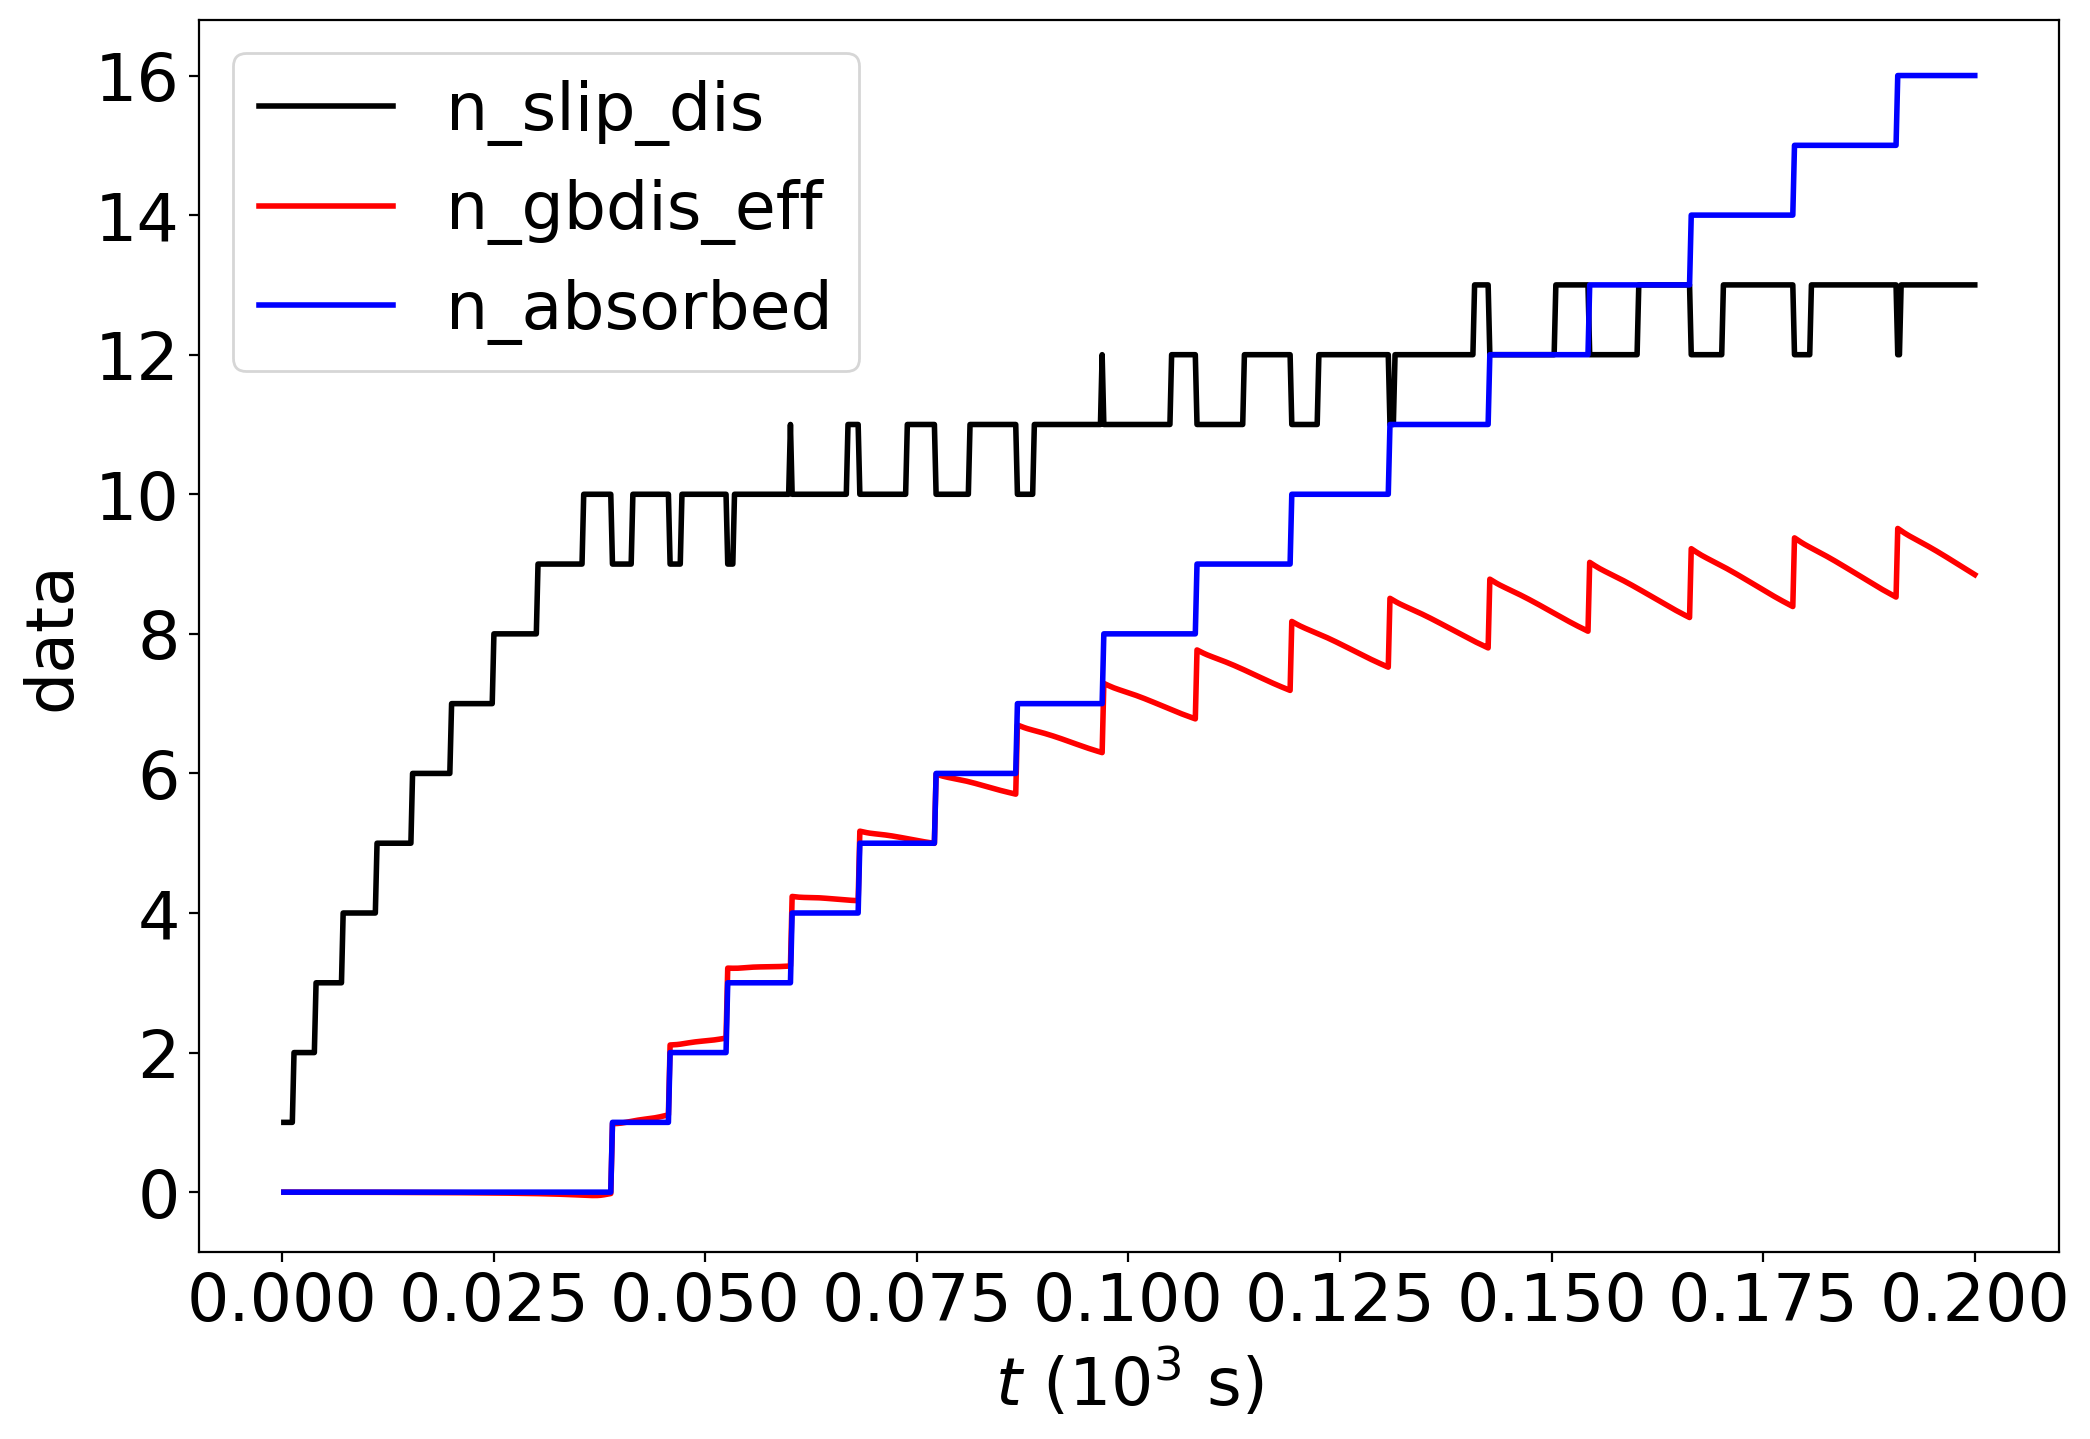

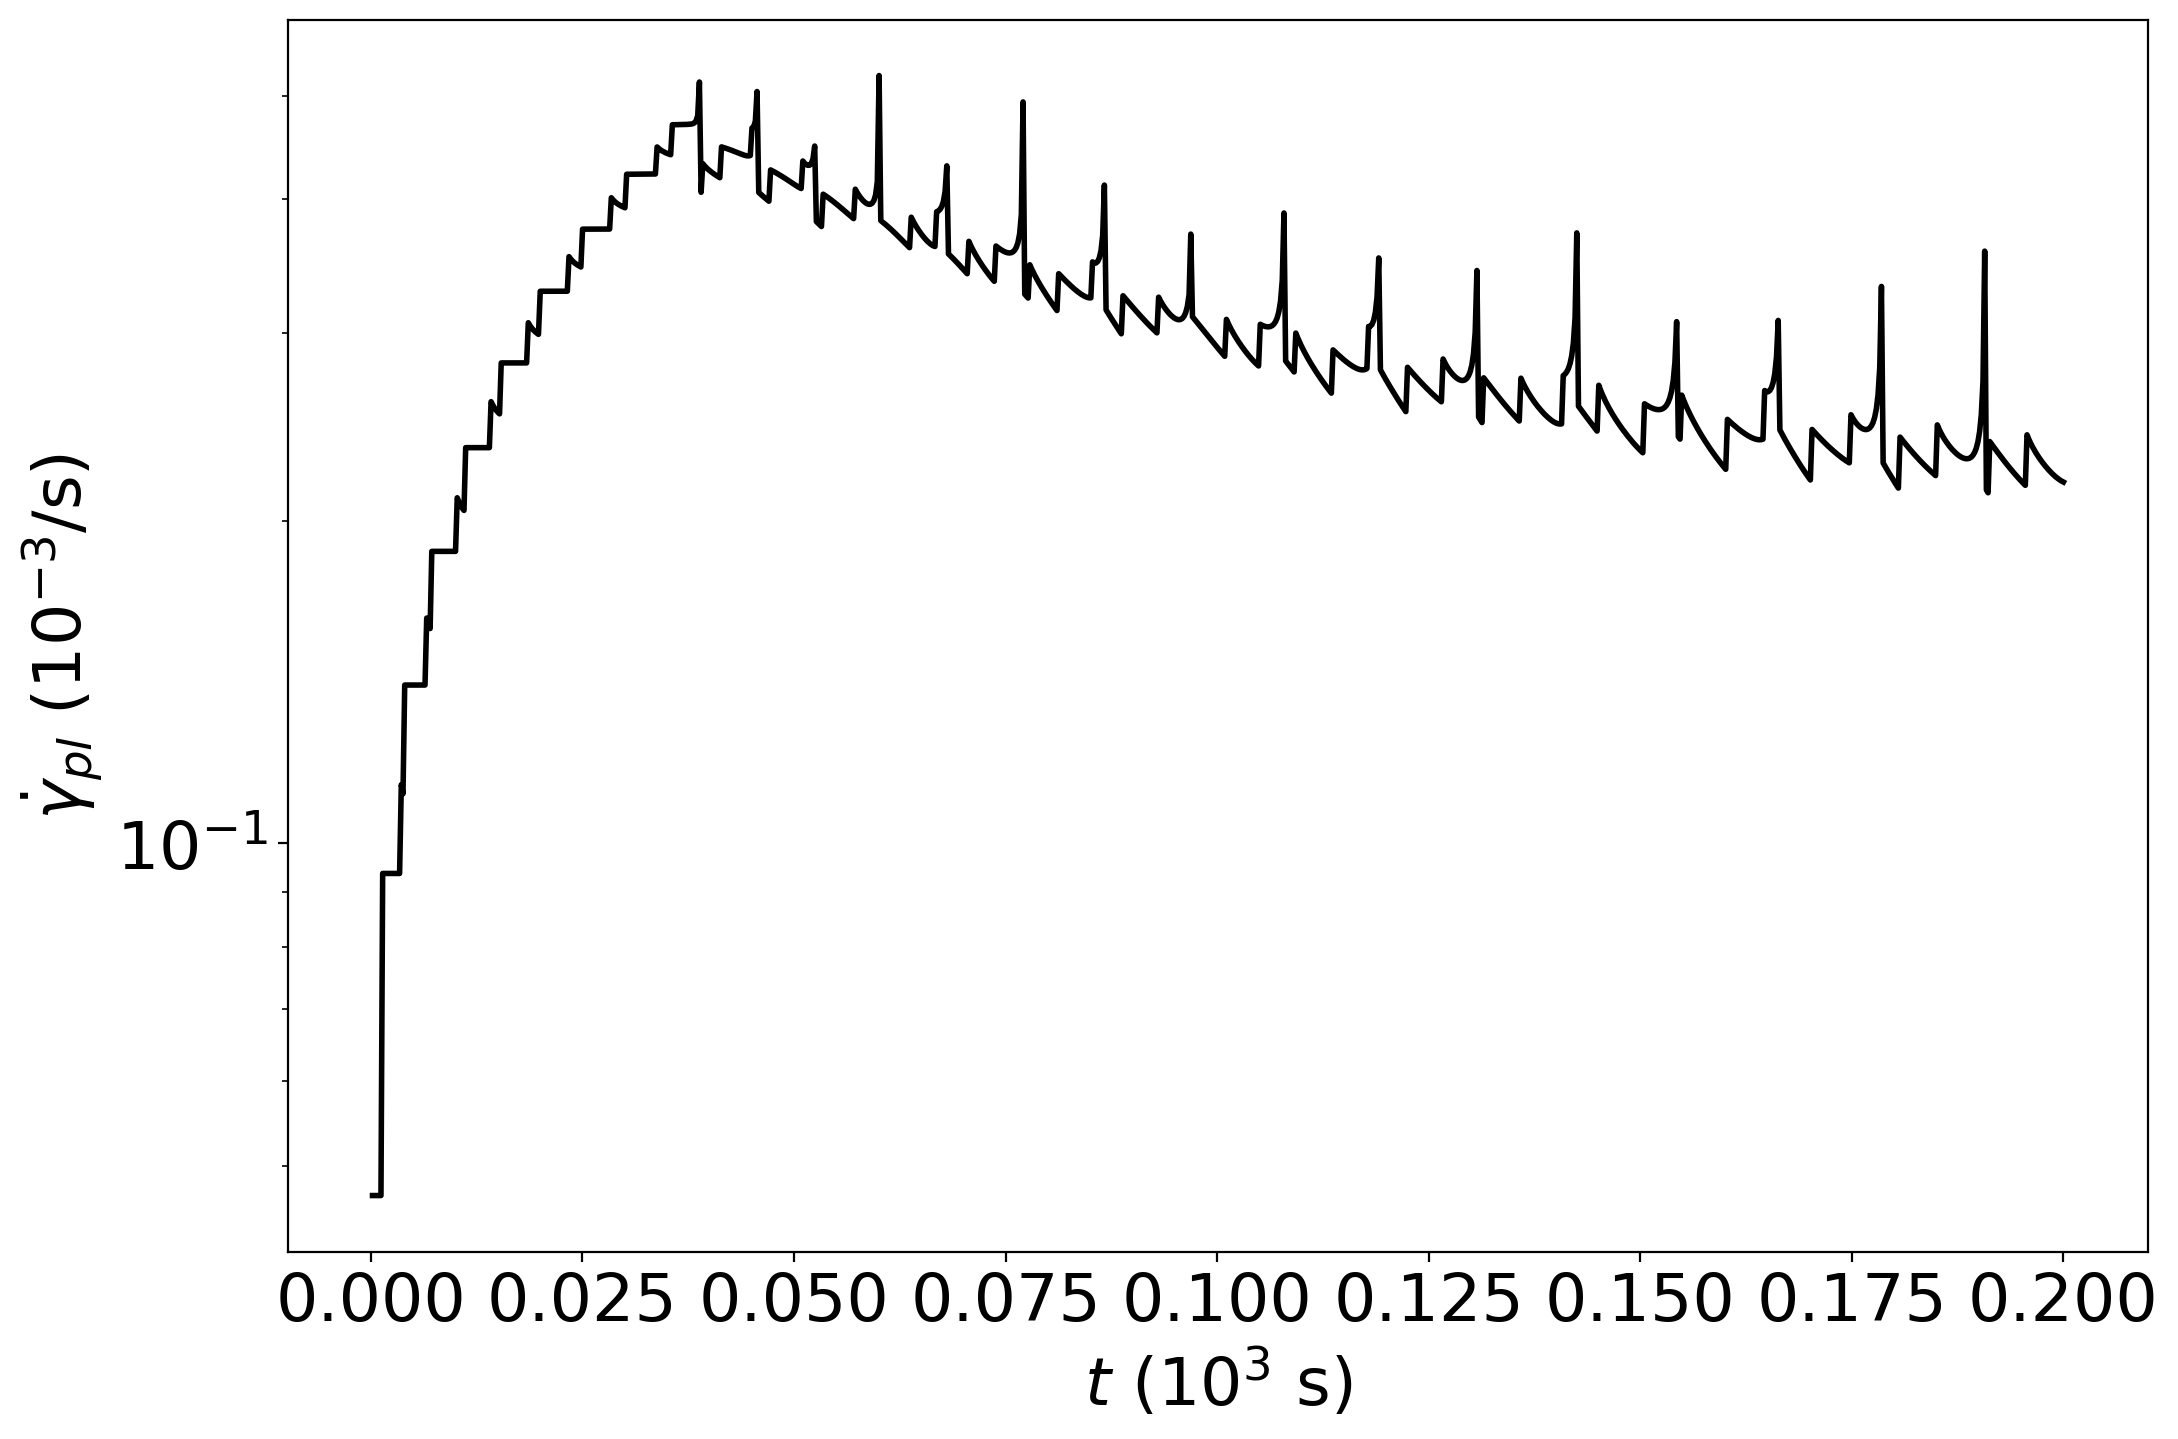

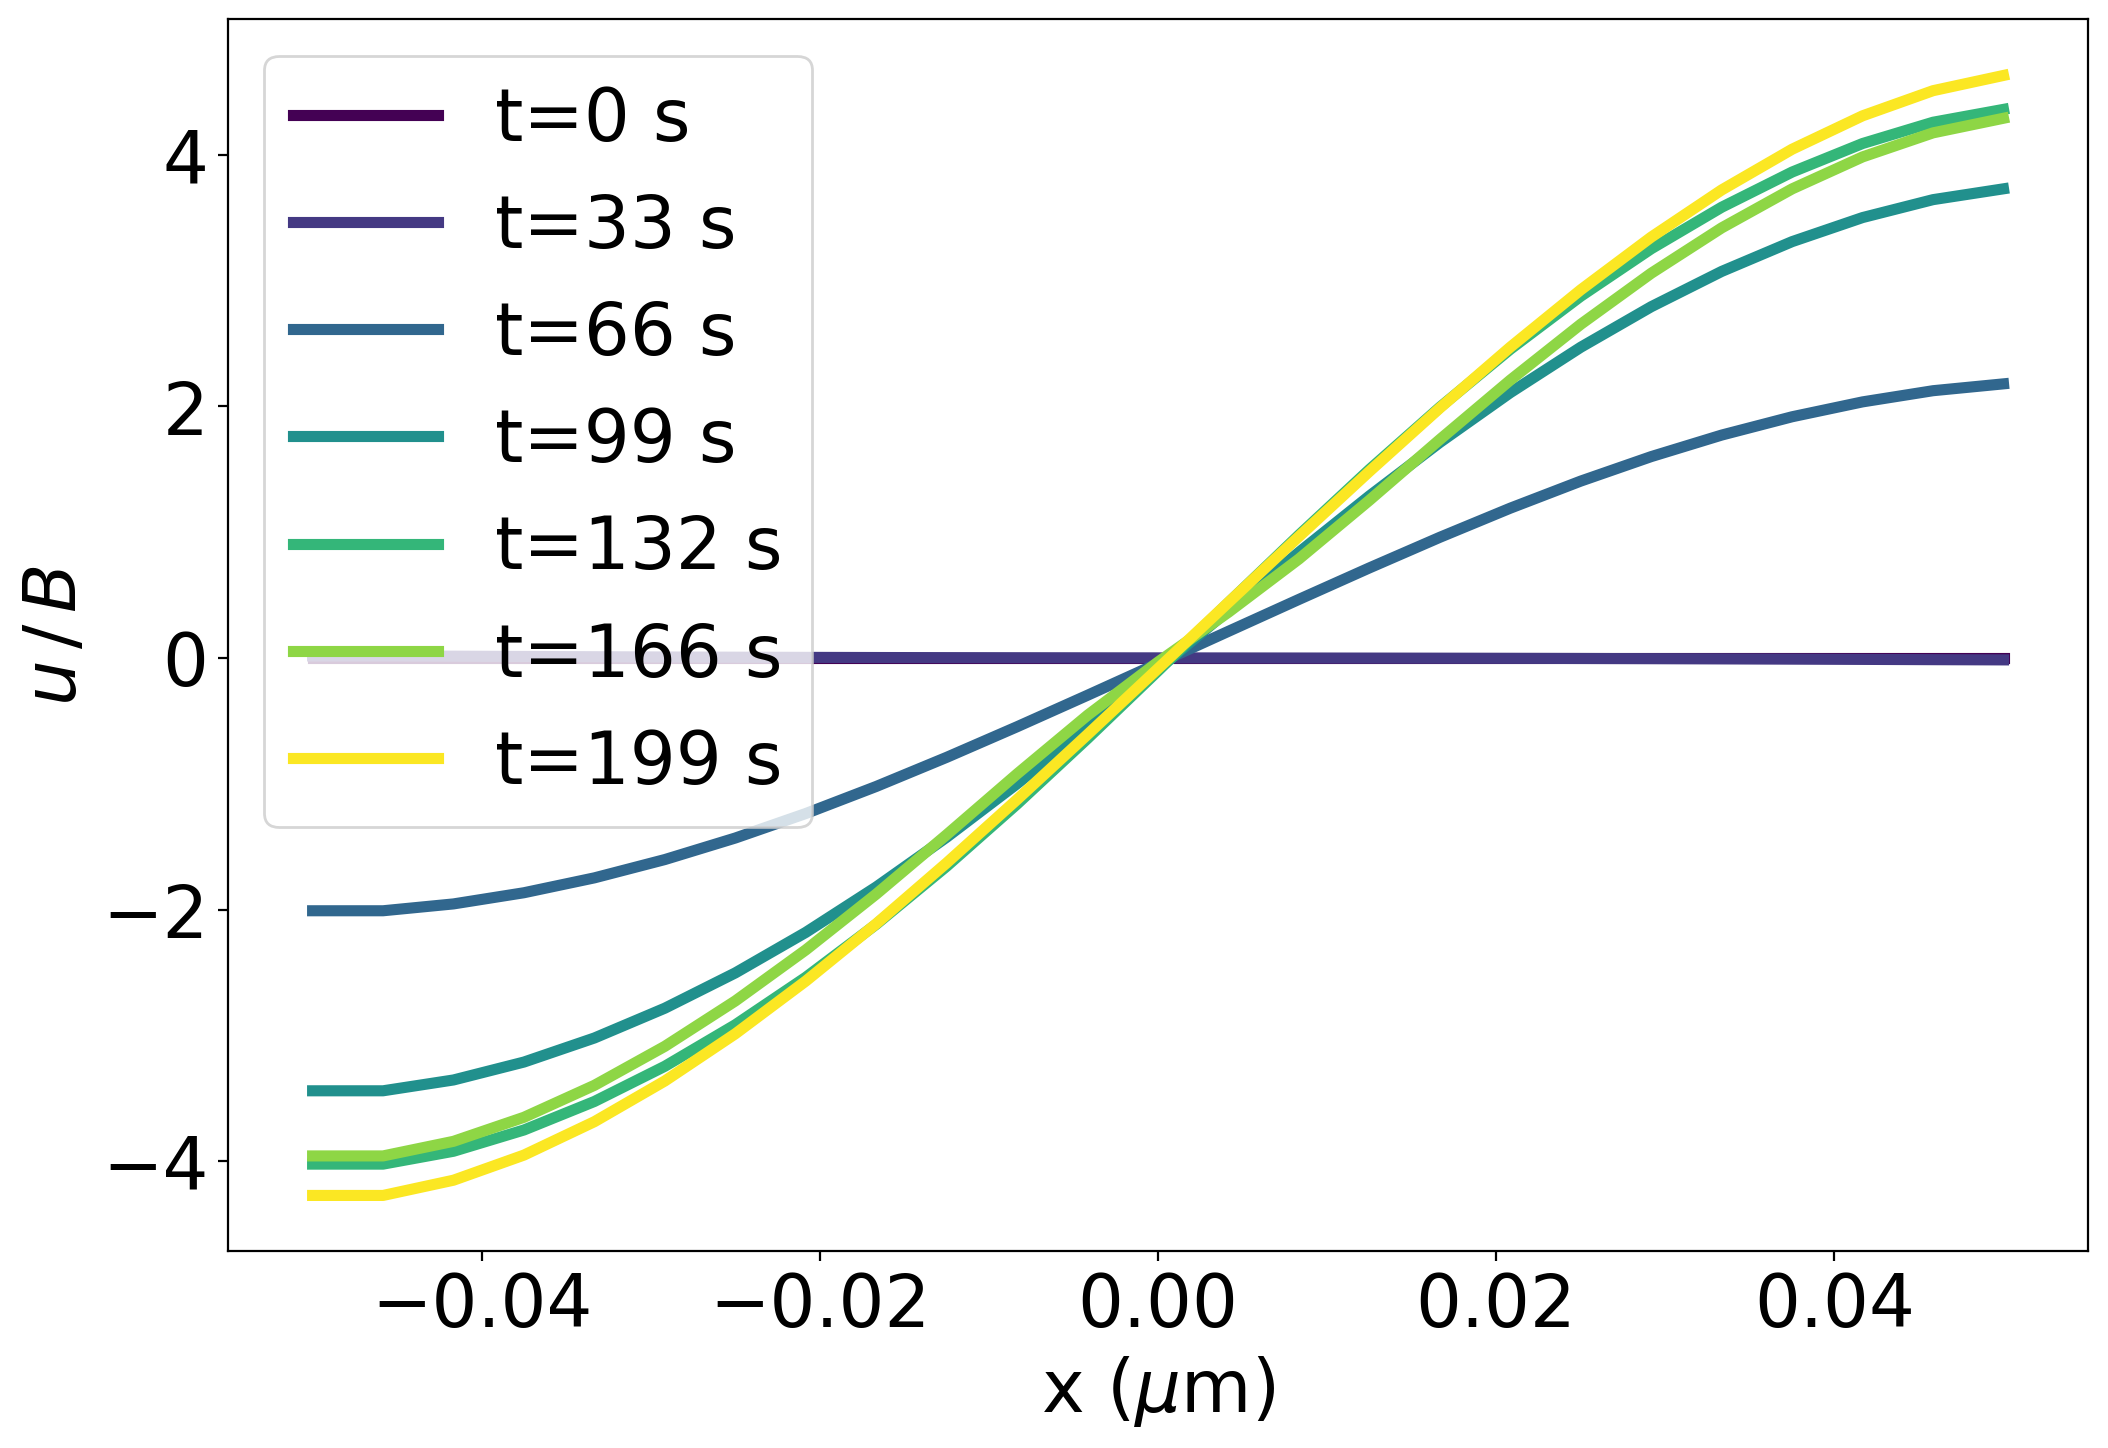

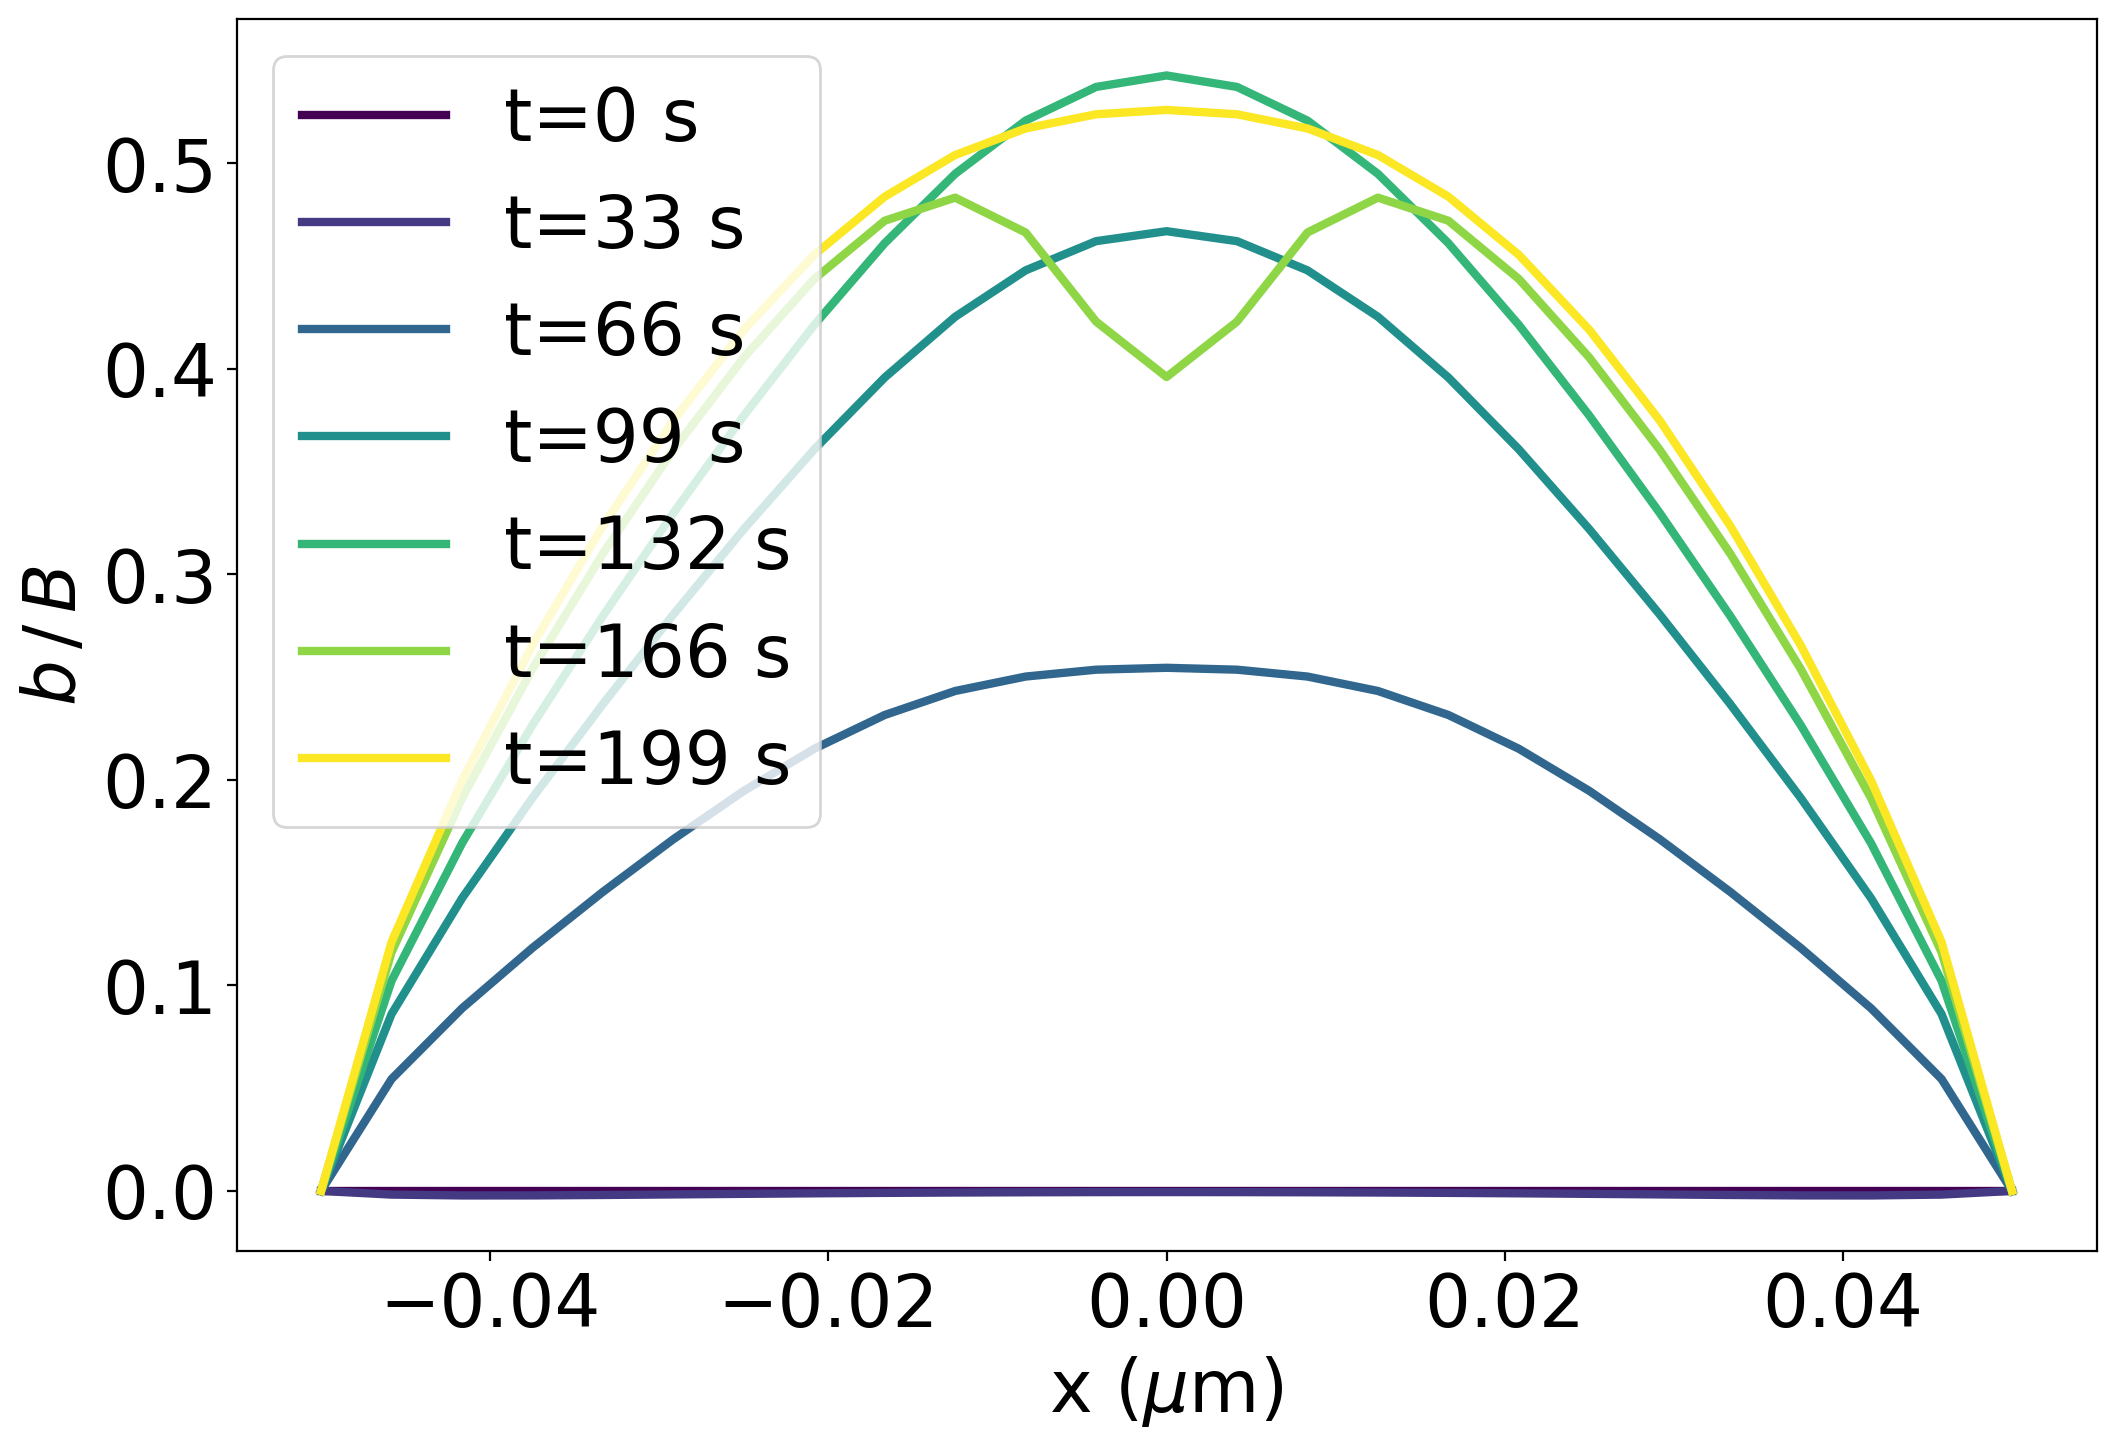

In [2]:
# set simulation parameters
temp = 900.0
tau0 = 150.0
gs = 1.0
lgb = 0.1
delta = 0.004
ngbn = int(lgb/delta)
if ngbn % 2 == 0: ngbn += 1
dtmax = 6.25e-7/delta**4  # value 1.e4 for delta=0.005, 50. for PU
#grain_size = 1.0
tfin = 0.2e9
niter = 10_000_000

# run simulation
print(f"Simulation with N_gbn={ngbn}, grain_size={gs}, dtmax={dtmax}")
gbdd0 = dd.GB_dislocations(temp=temp, tau0=tau0,
                    Ngbn=ngbn, len_gb_seg=lgb, grain_size=gs,
                    tfin=tfin, niter=niter, maxout=maxout,
                    dtmax=dtmax,
                    screenout=True)
gbdd0.run_sim()
gbdd0.save_hdf5(f"pu_test{int(tau0)}_T{int(temp)}_D{int(gs*10)}.h5")
gbdd0.plot_time_series(['n_slip_dis', 'n_gbdis_eff', 'n_absorbed'])
gbdd0.plot_time_series('plast_slip_rate')
gbdd0.plot_field('displacement', fs=26, lw=4, nplot=6,
                  file=f"tau{int(tau0)}_T{int(temp)}_D{int(gs*10)}.pdf")
gbdd0.plot_field('bfield', fs=26, lw=3, nplot=6,
                  file=f"tau{int(tau0)}_T{int(temp)}_D{int(gs*10)}.pdf")



Set drag: 500.0
Set nu: 0.3
Set mu: 44000.0
Set B: 0.00025
 Starting iteration for T, tau0, D2, Lgb, Ngbn   900.00000000000000        150.00000000000000        1.0000000000000000       0.10000000000000001               25
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      100000   96.611297822333484        39.247095789939166        2.5231076956566124E-011   2.4549626660706156E-004           9           1  0.97415529338452089     
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      200000   502.42306596362761        47.387821267757516        4.8518756990726094E-012   5.3168816446439338E-004          10           2  0.99900161891677508     
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      300000   830.45473321361646        57.657869867985390        2.9441904595269397E-012   8.0723184406272103E-004          10           3  0.96918700164952765     
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      400000 

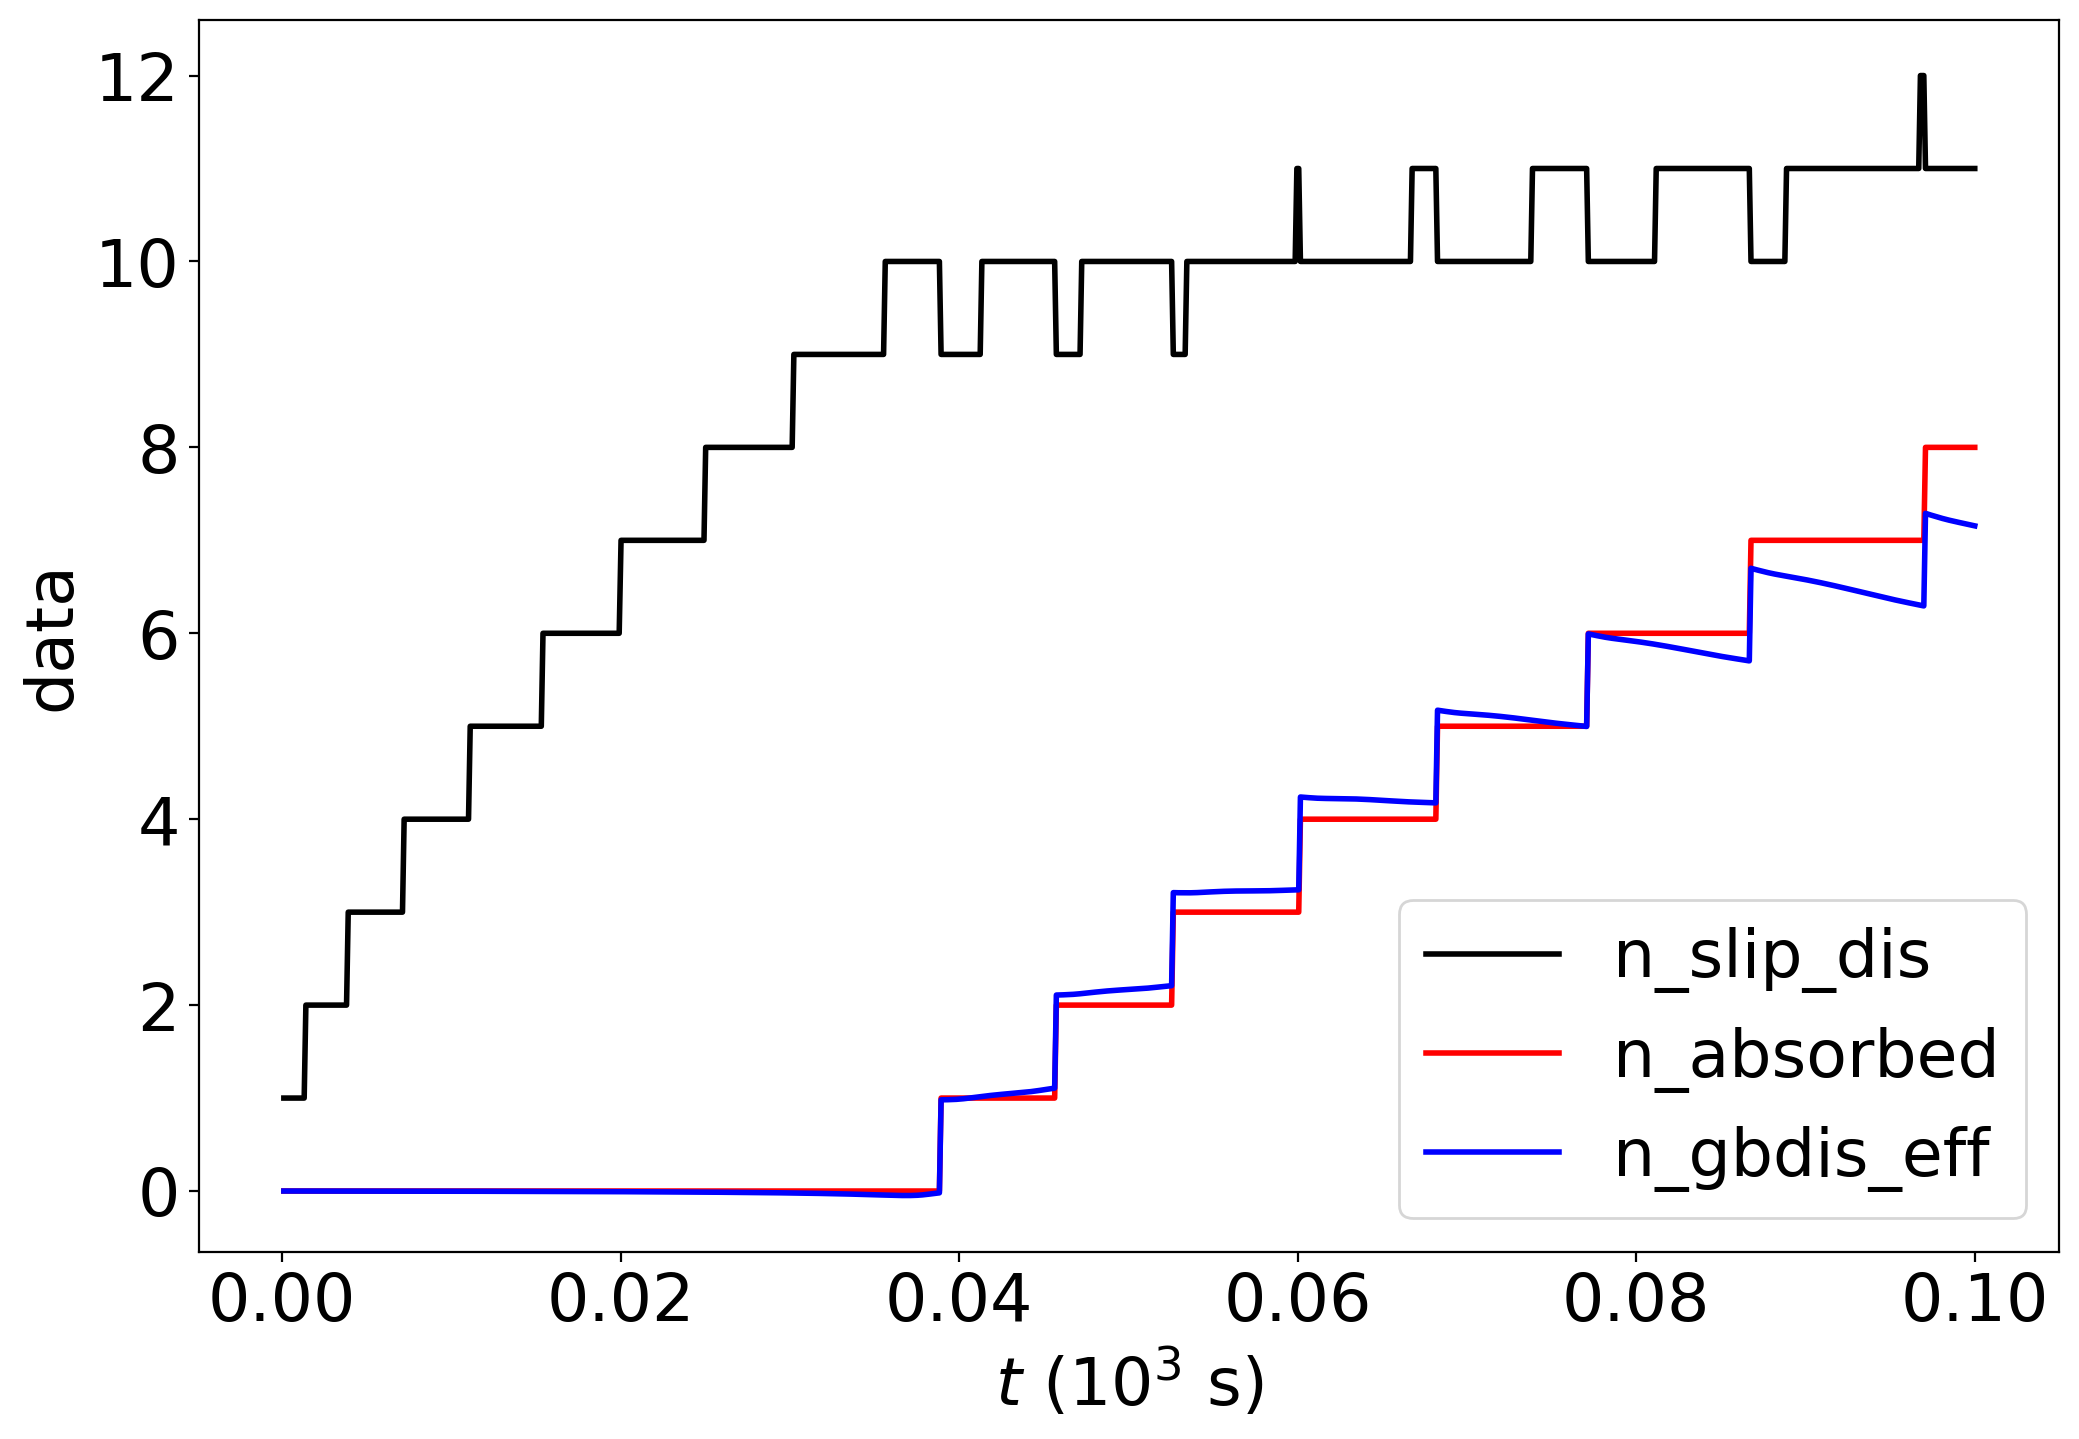

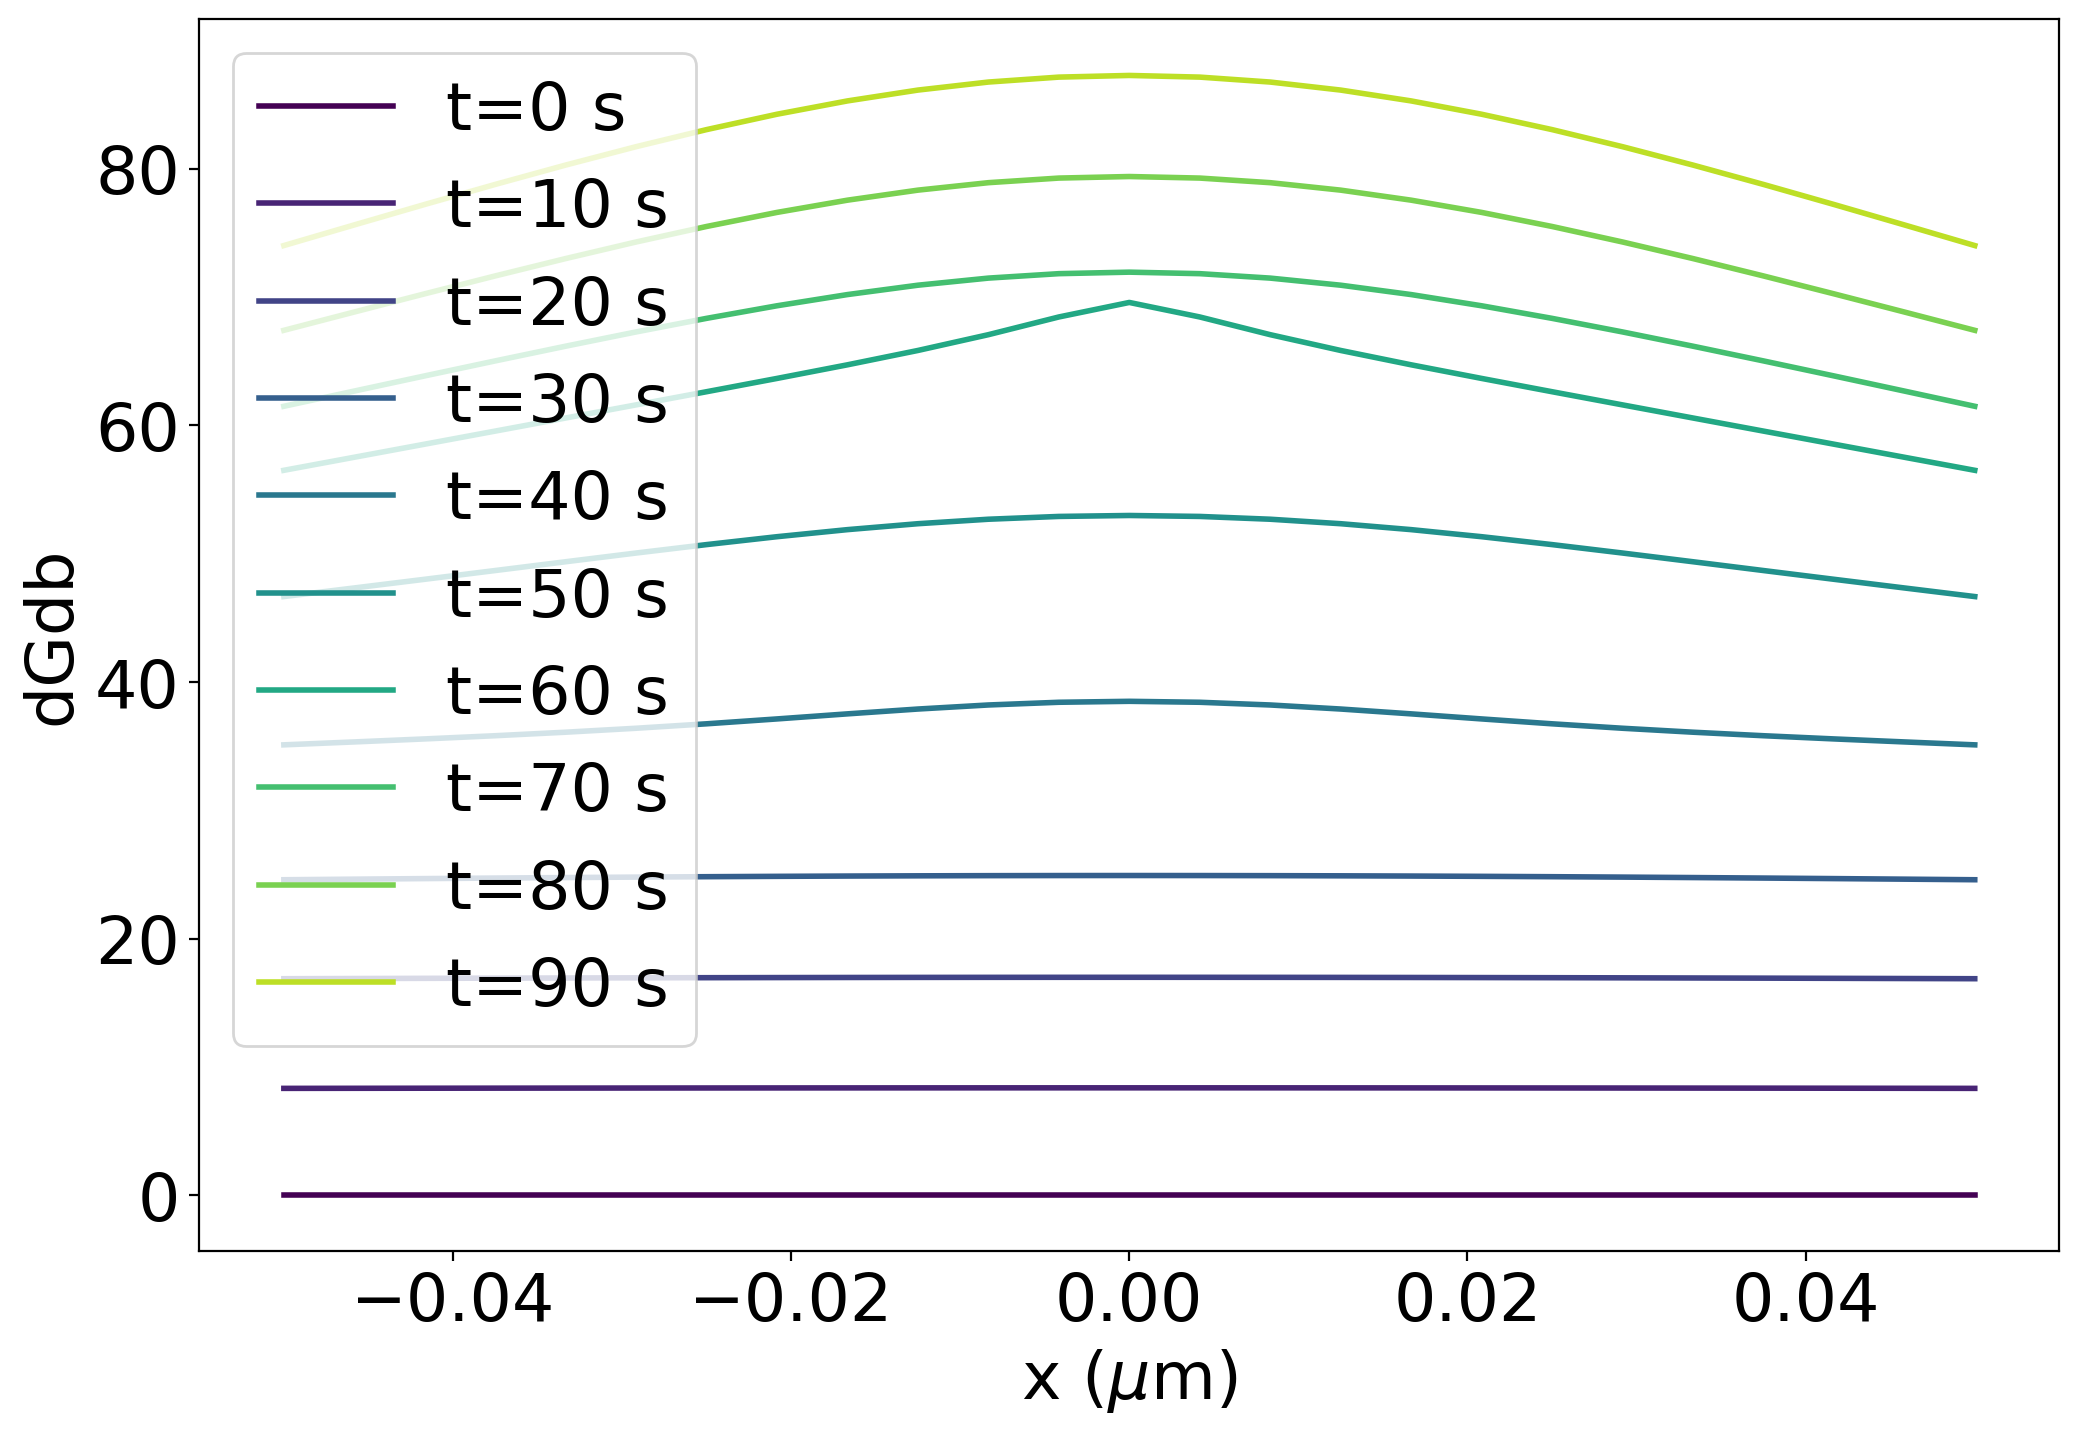

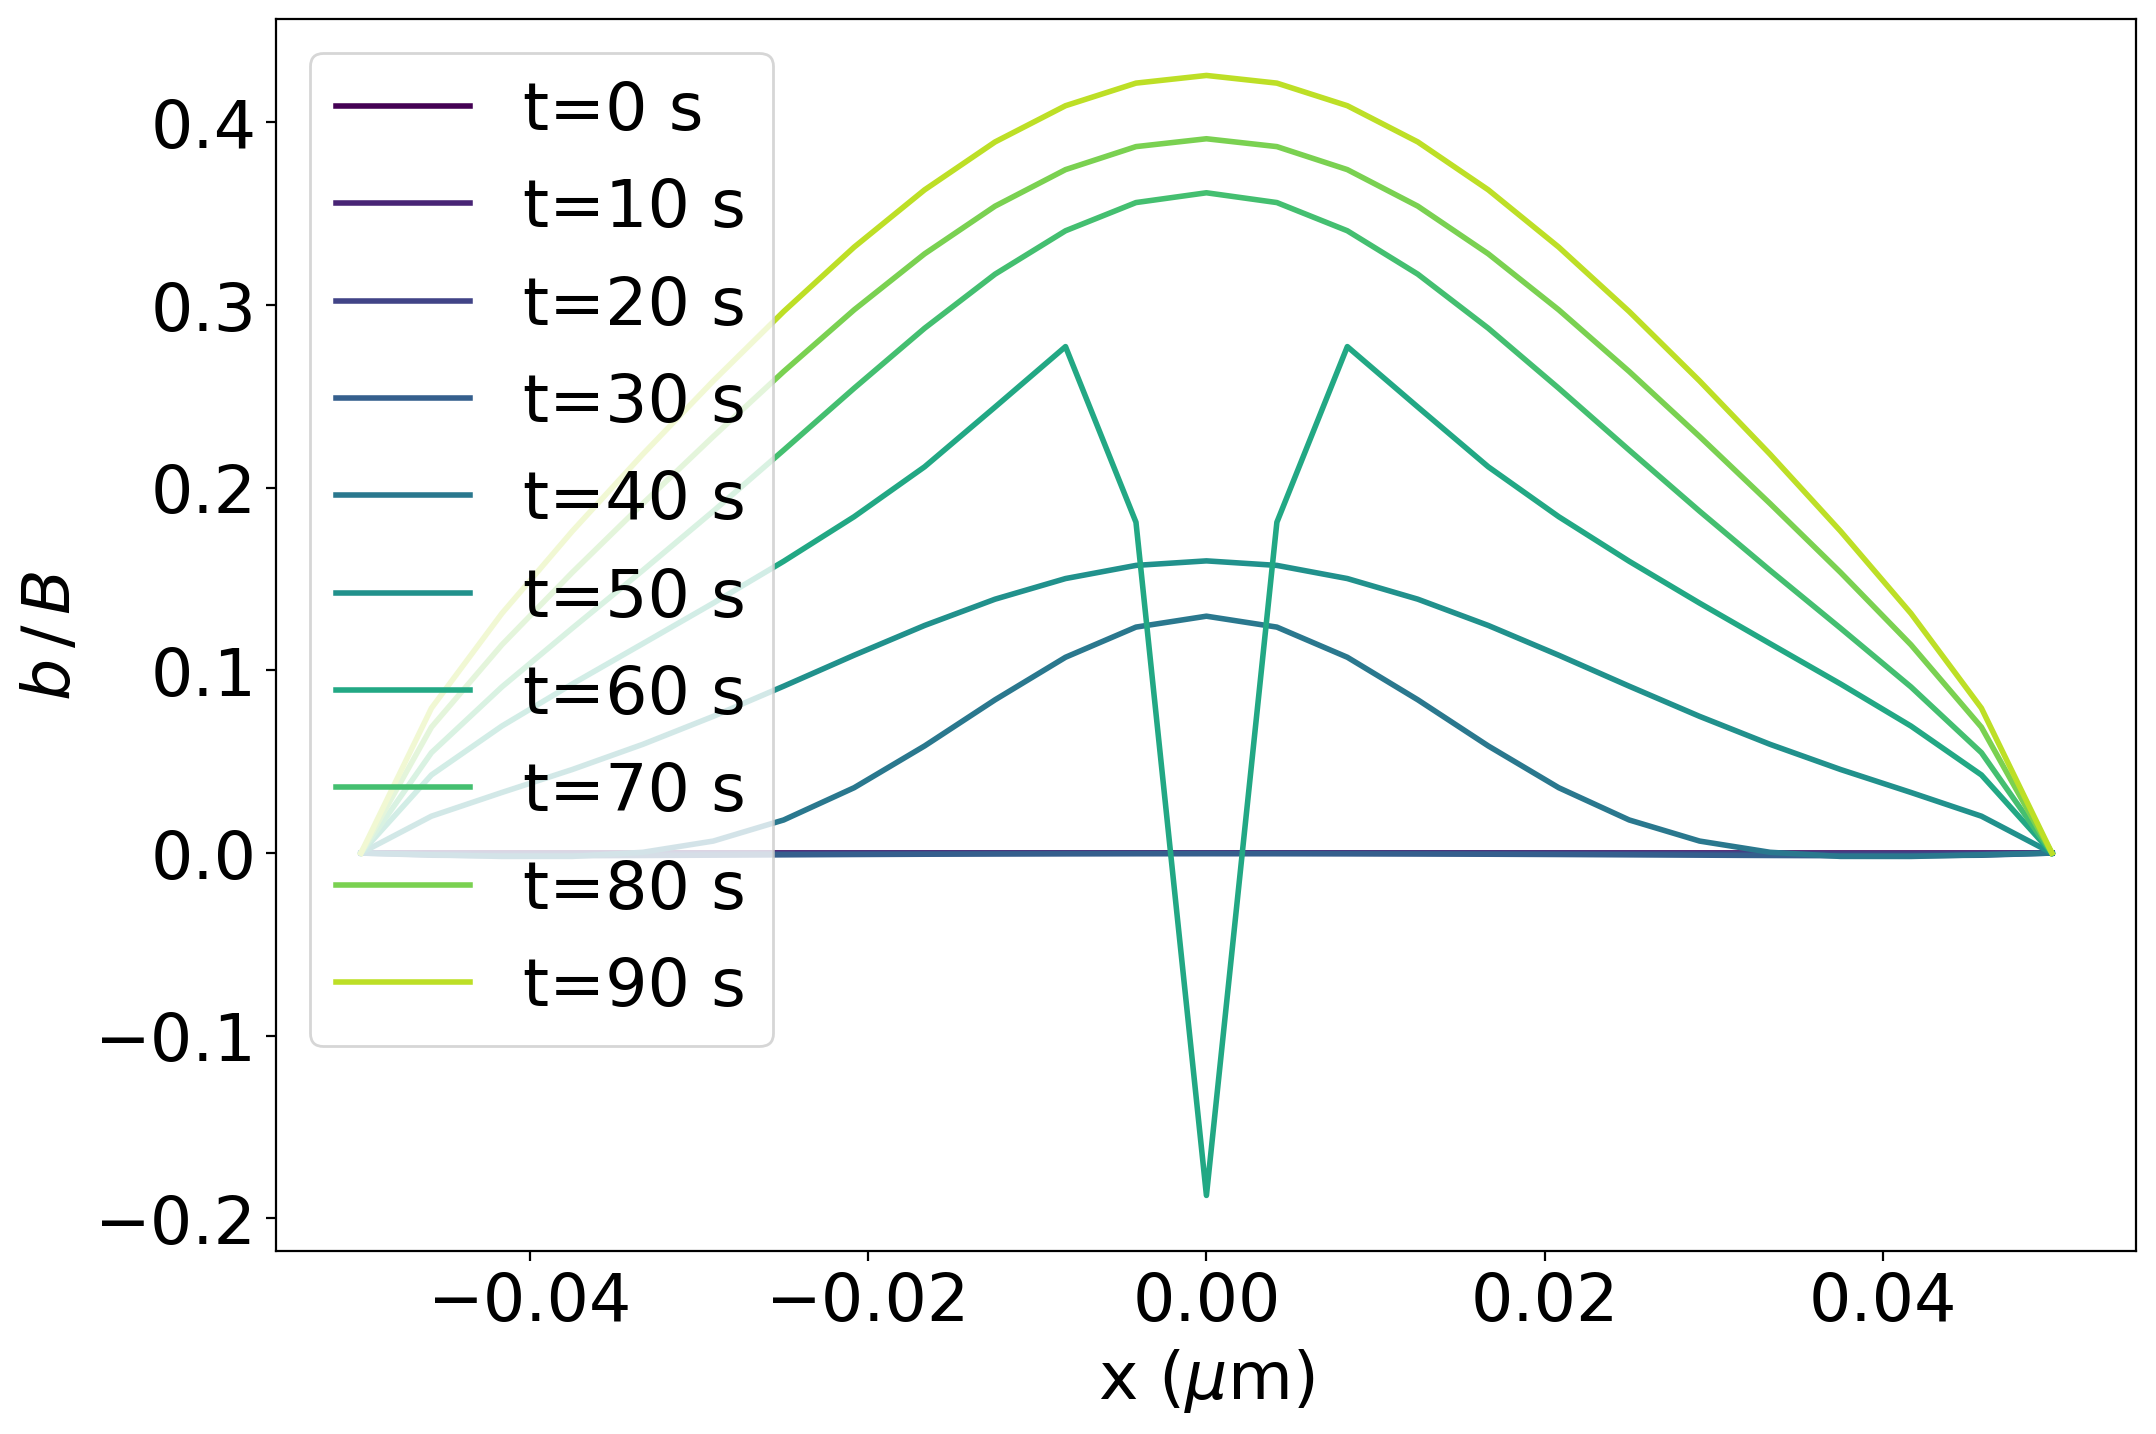

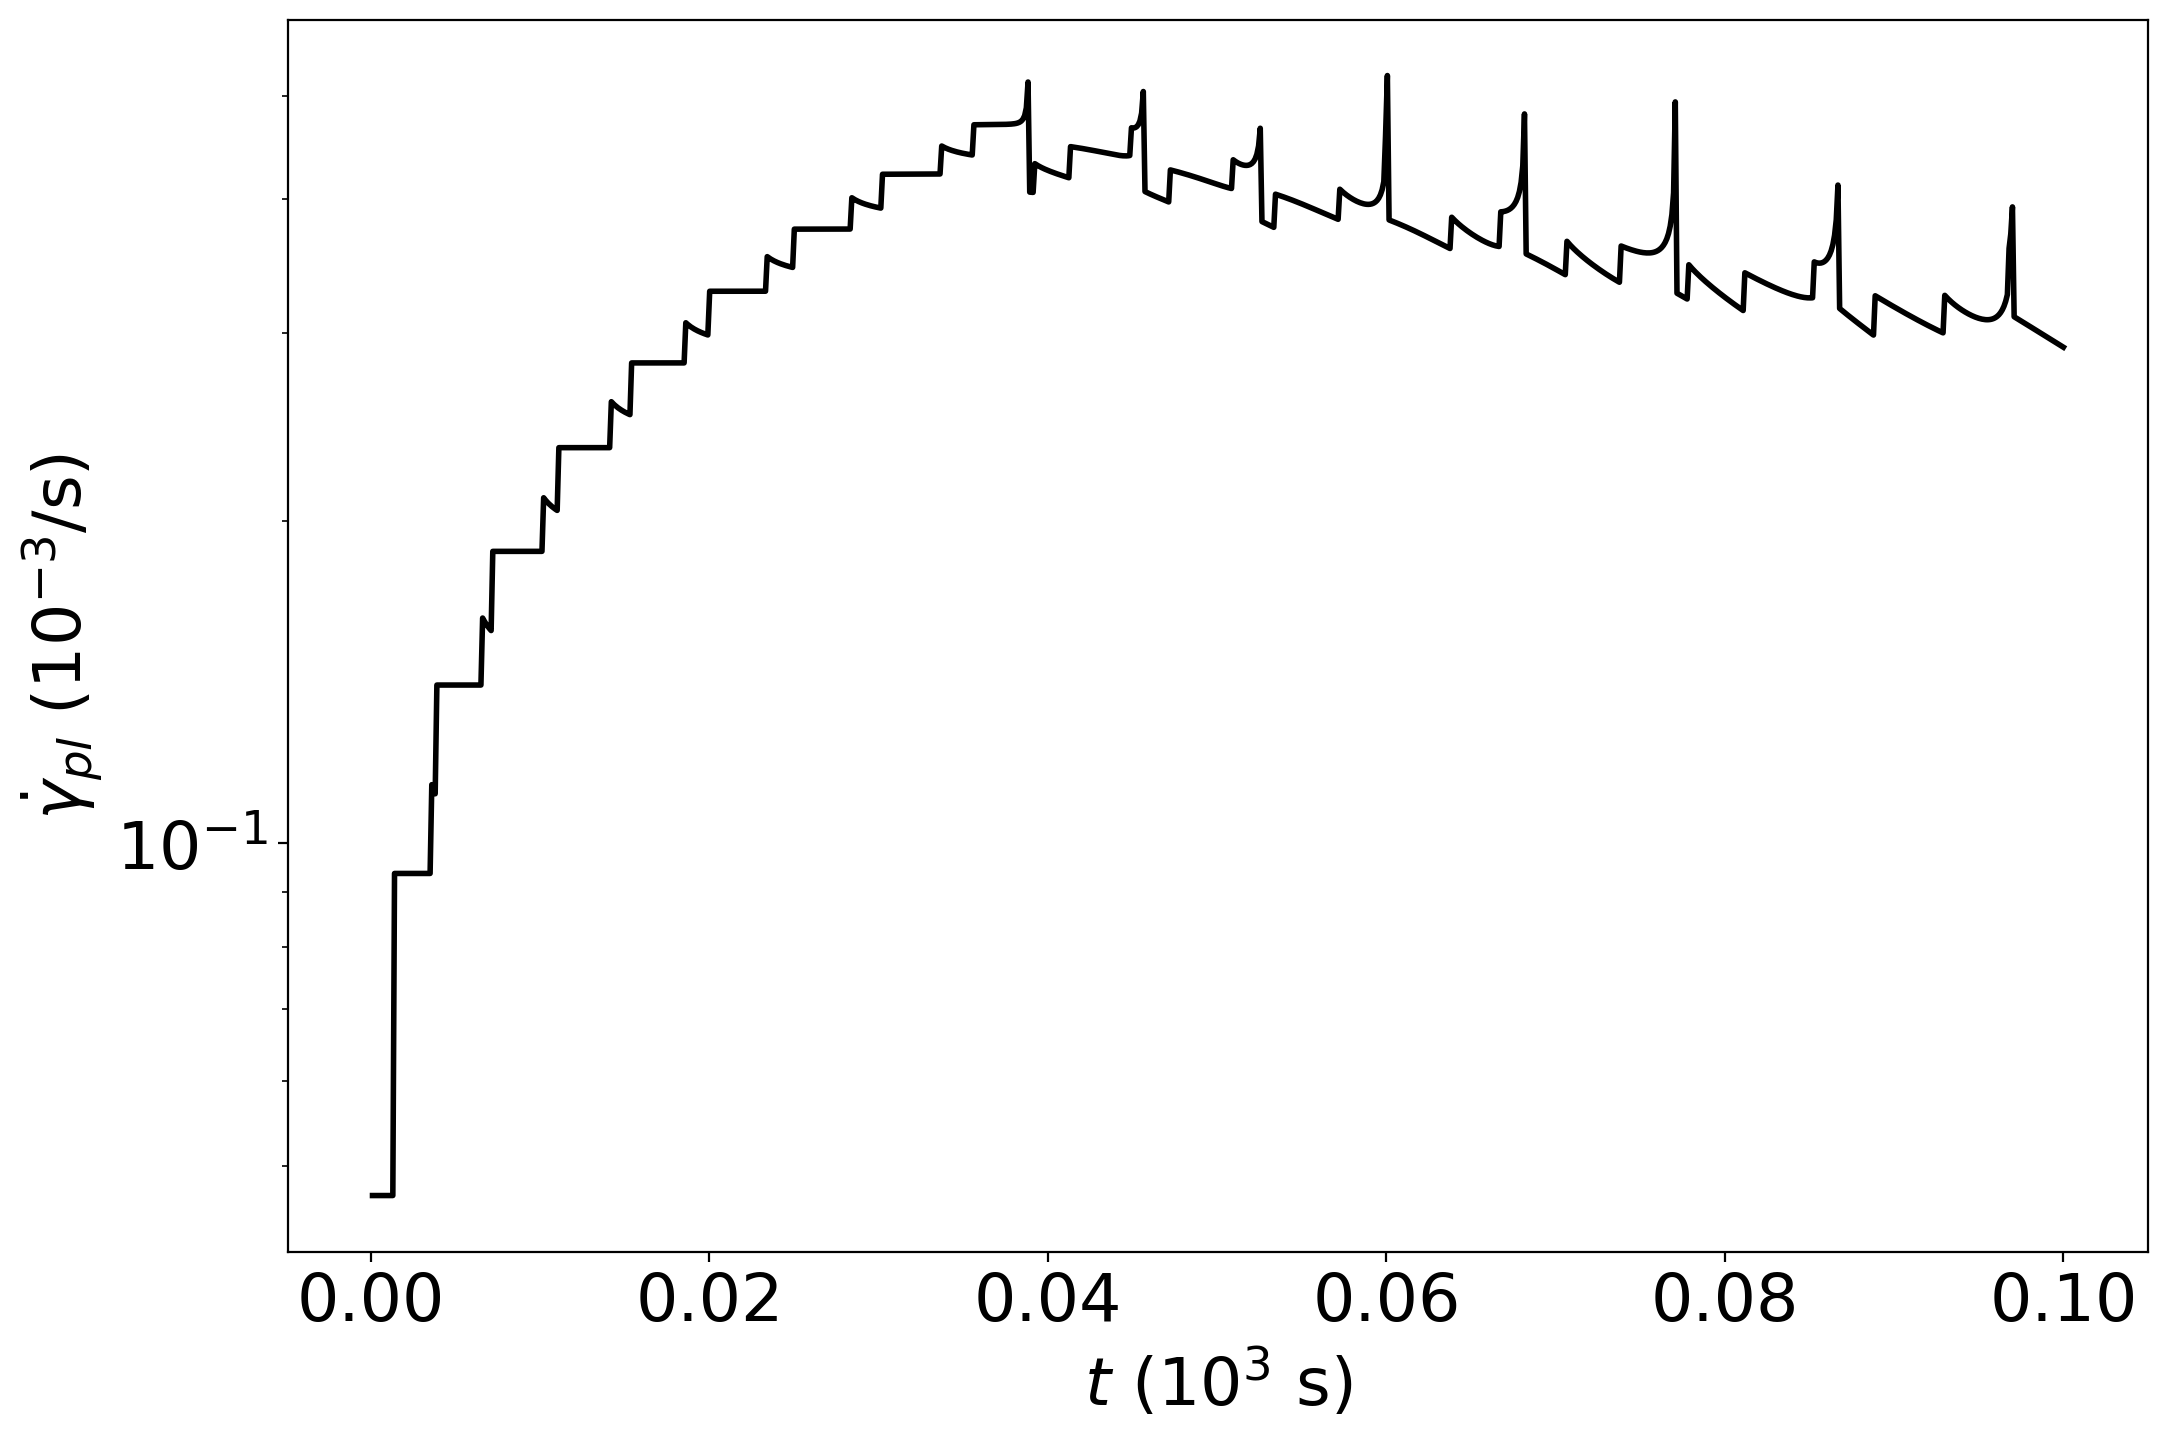

In [3]:
# Set pre-existing dislocations in pile-up
fill_fact = 0.5
b0 = 0.25e-3
nu = 0.3
mu = 44.e3
drag = 500.
hc = mu*b0/(2*np.pi*(1.-nu))   # Constant for dislocation stress field
Ntot = int(fill_fact*np.pi*(1-nu)*gs*tau0/(mu*b0)) # total number of dislocations
dmax = np.pi**2*gs / (64*fill_fact*Ntot**2)  # distance of first dislocation to GB = maximum travel distance per time step
ypos = np.zeros(Ntot)
ypos[1] = dmax
for i in range(2, Ntot):
    x0 = ypos[i-1]
    ypos[i] = x0 + np.pi*hc / (tau0*np.sqrt((gs*fill_fact-x0)/x0))

# Run gbdd simulation
gbdd = dd.GB_dislocations(temp=temp, tau0=tau0,
                   Ngbn=ngbn, len_gb_seg=lgb, grain_size=gs,
                   tfin=tfin*0.5, niter=niter, maxout=maxout,
                   dtmax=dtmax, drag=drag,
                   nu=nu, mu=mu, B=b0,
                   screenout=True)
gbdd.run_sim()  # pudis=ypos.copy())
gbdd.save_hdf5(f"gbpre_tau{int(tau0)}_T{int(temp)}_H{int(gs*10)}_L{int(lgb*10)}.h5")
gbdd.plot_time_series( ["n_slip_dis", "n_absorbed", "n_gbdis_eff"])
gbdd.plot_field('dGdb')
gbdd.plot_field("bfield")
gbdd.plot_time_series("plast_slip_rate")

Set drag: 500.0
Set nu: 0.3
Set mu: 44000.0
Set B: 0.00025
 Restarting simulation from time =   100000257.90909223     
 with Npu =          11
 and Nabs absorbed dislocations: Nabs =           8
 Starting iteration for T, tau0, D2, Lgb, Ngbn   900.00000000000000        150.00000000000000        1.0000000000000000       0.10000000000000001               25
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      100000   856.77426896337192        111.20585421477475        2.8476863019881951E-012   1.9027119966069299E-003          11           9  0.95276924342564162     
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      200000   838.47814300202049        122.41861573407208        2.9098268377186363E-012   2.0006594395204176E-003          12          10  0.99958576915358122     
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      300000   775.46264960456074        133.60362806774140        3.1458651807137301E-012   2.08648256984483

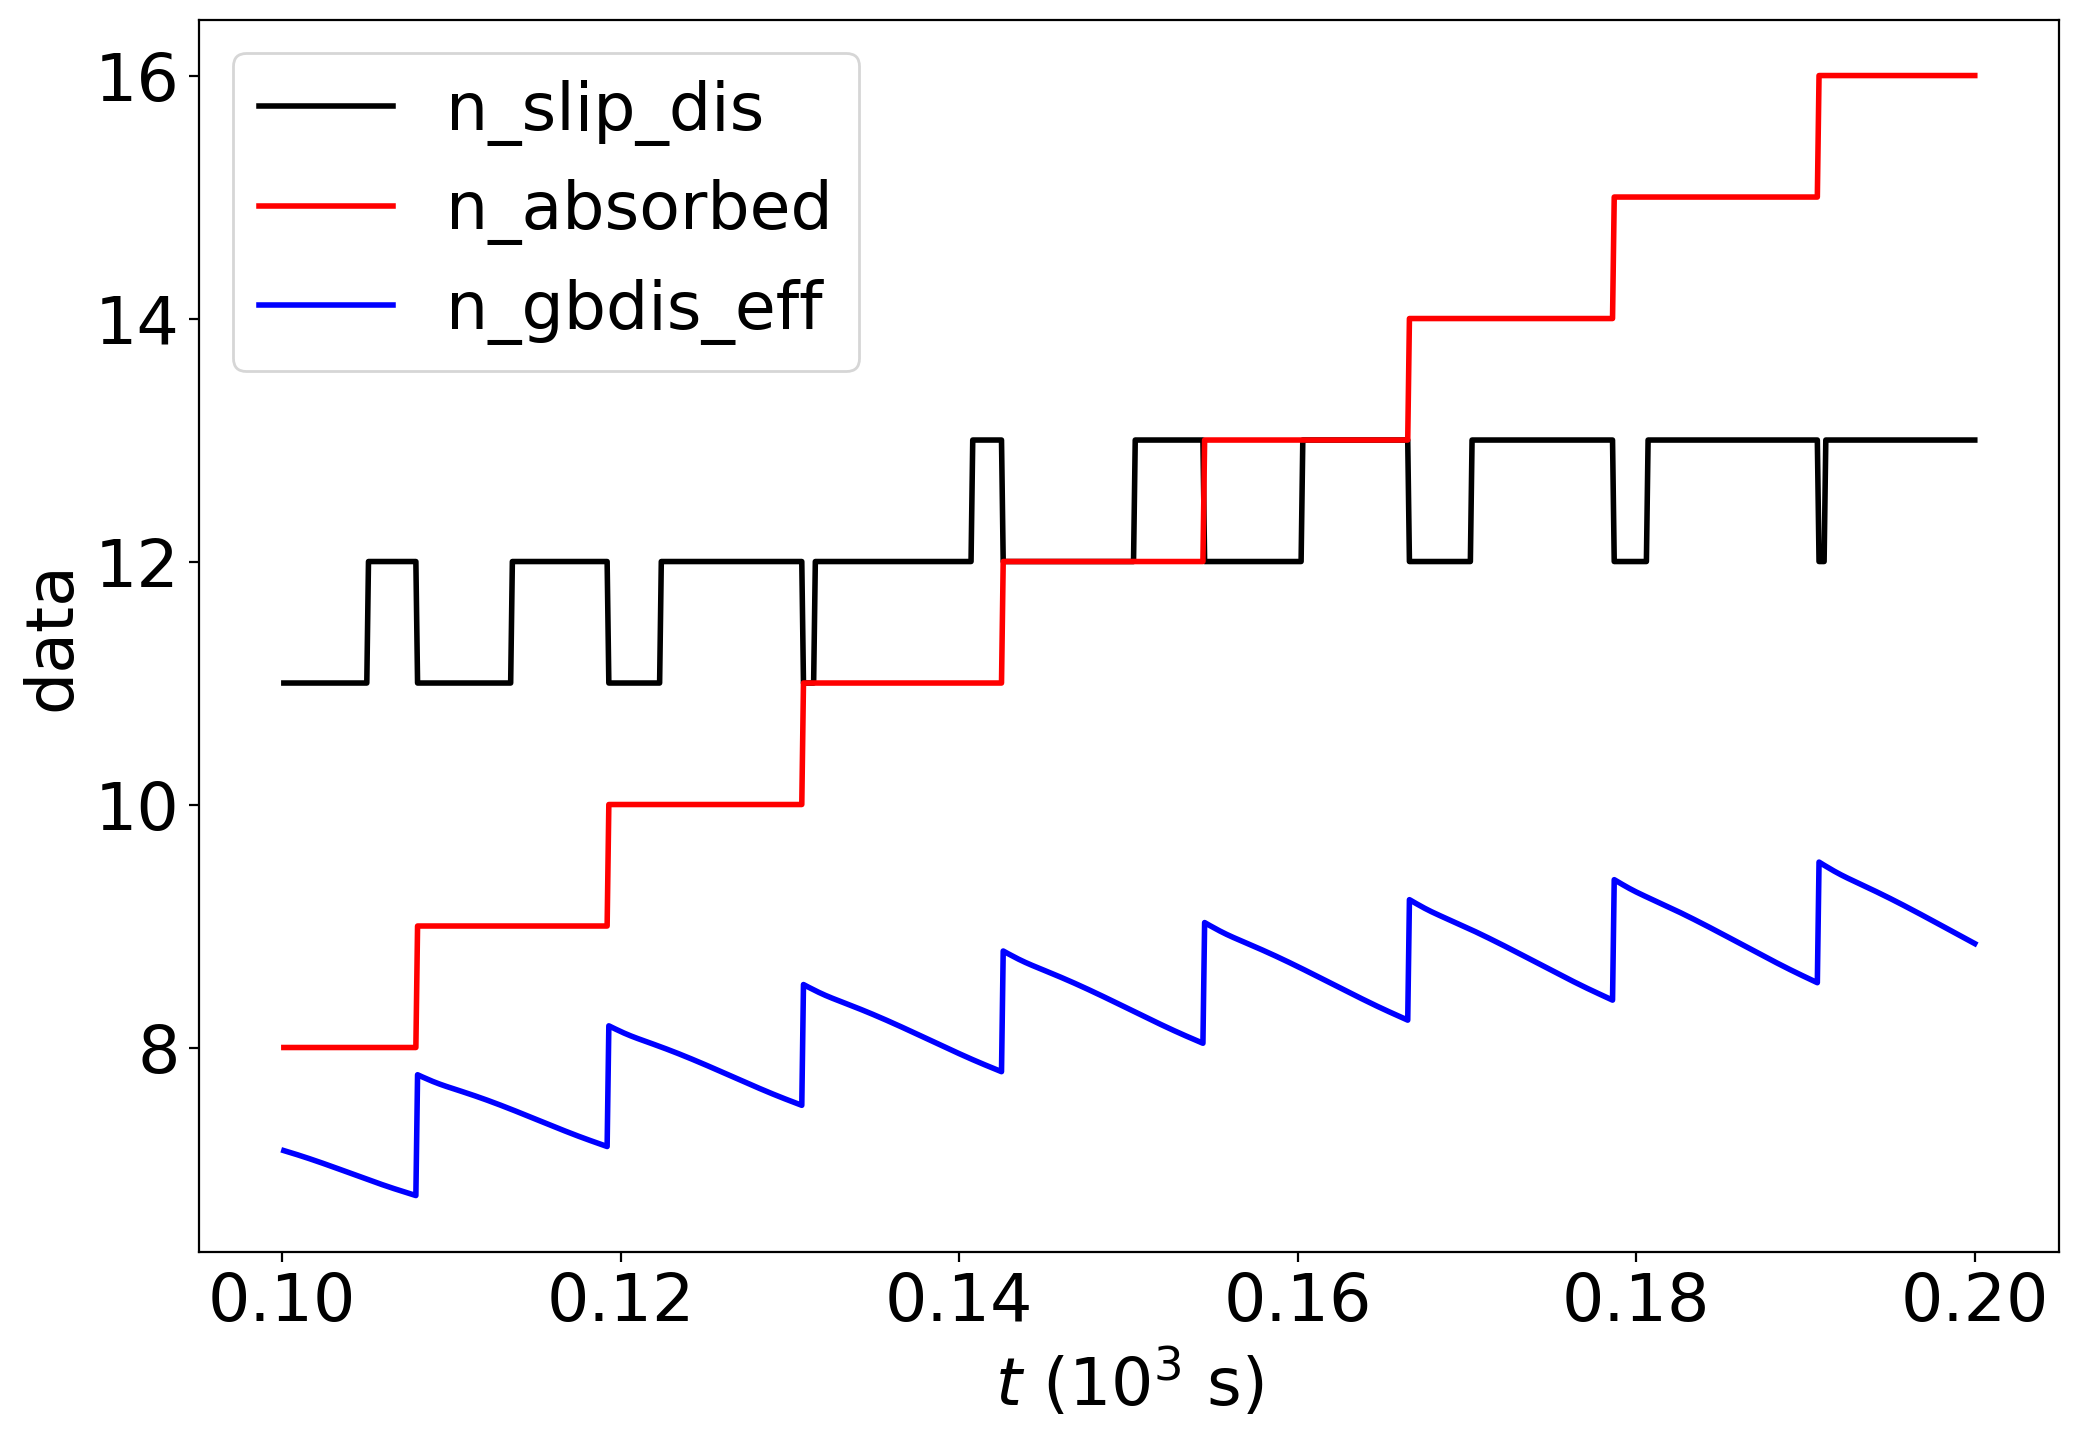

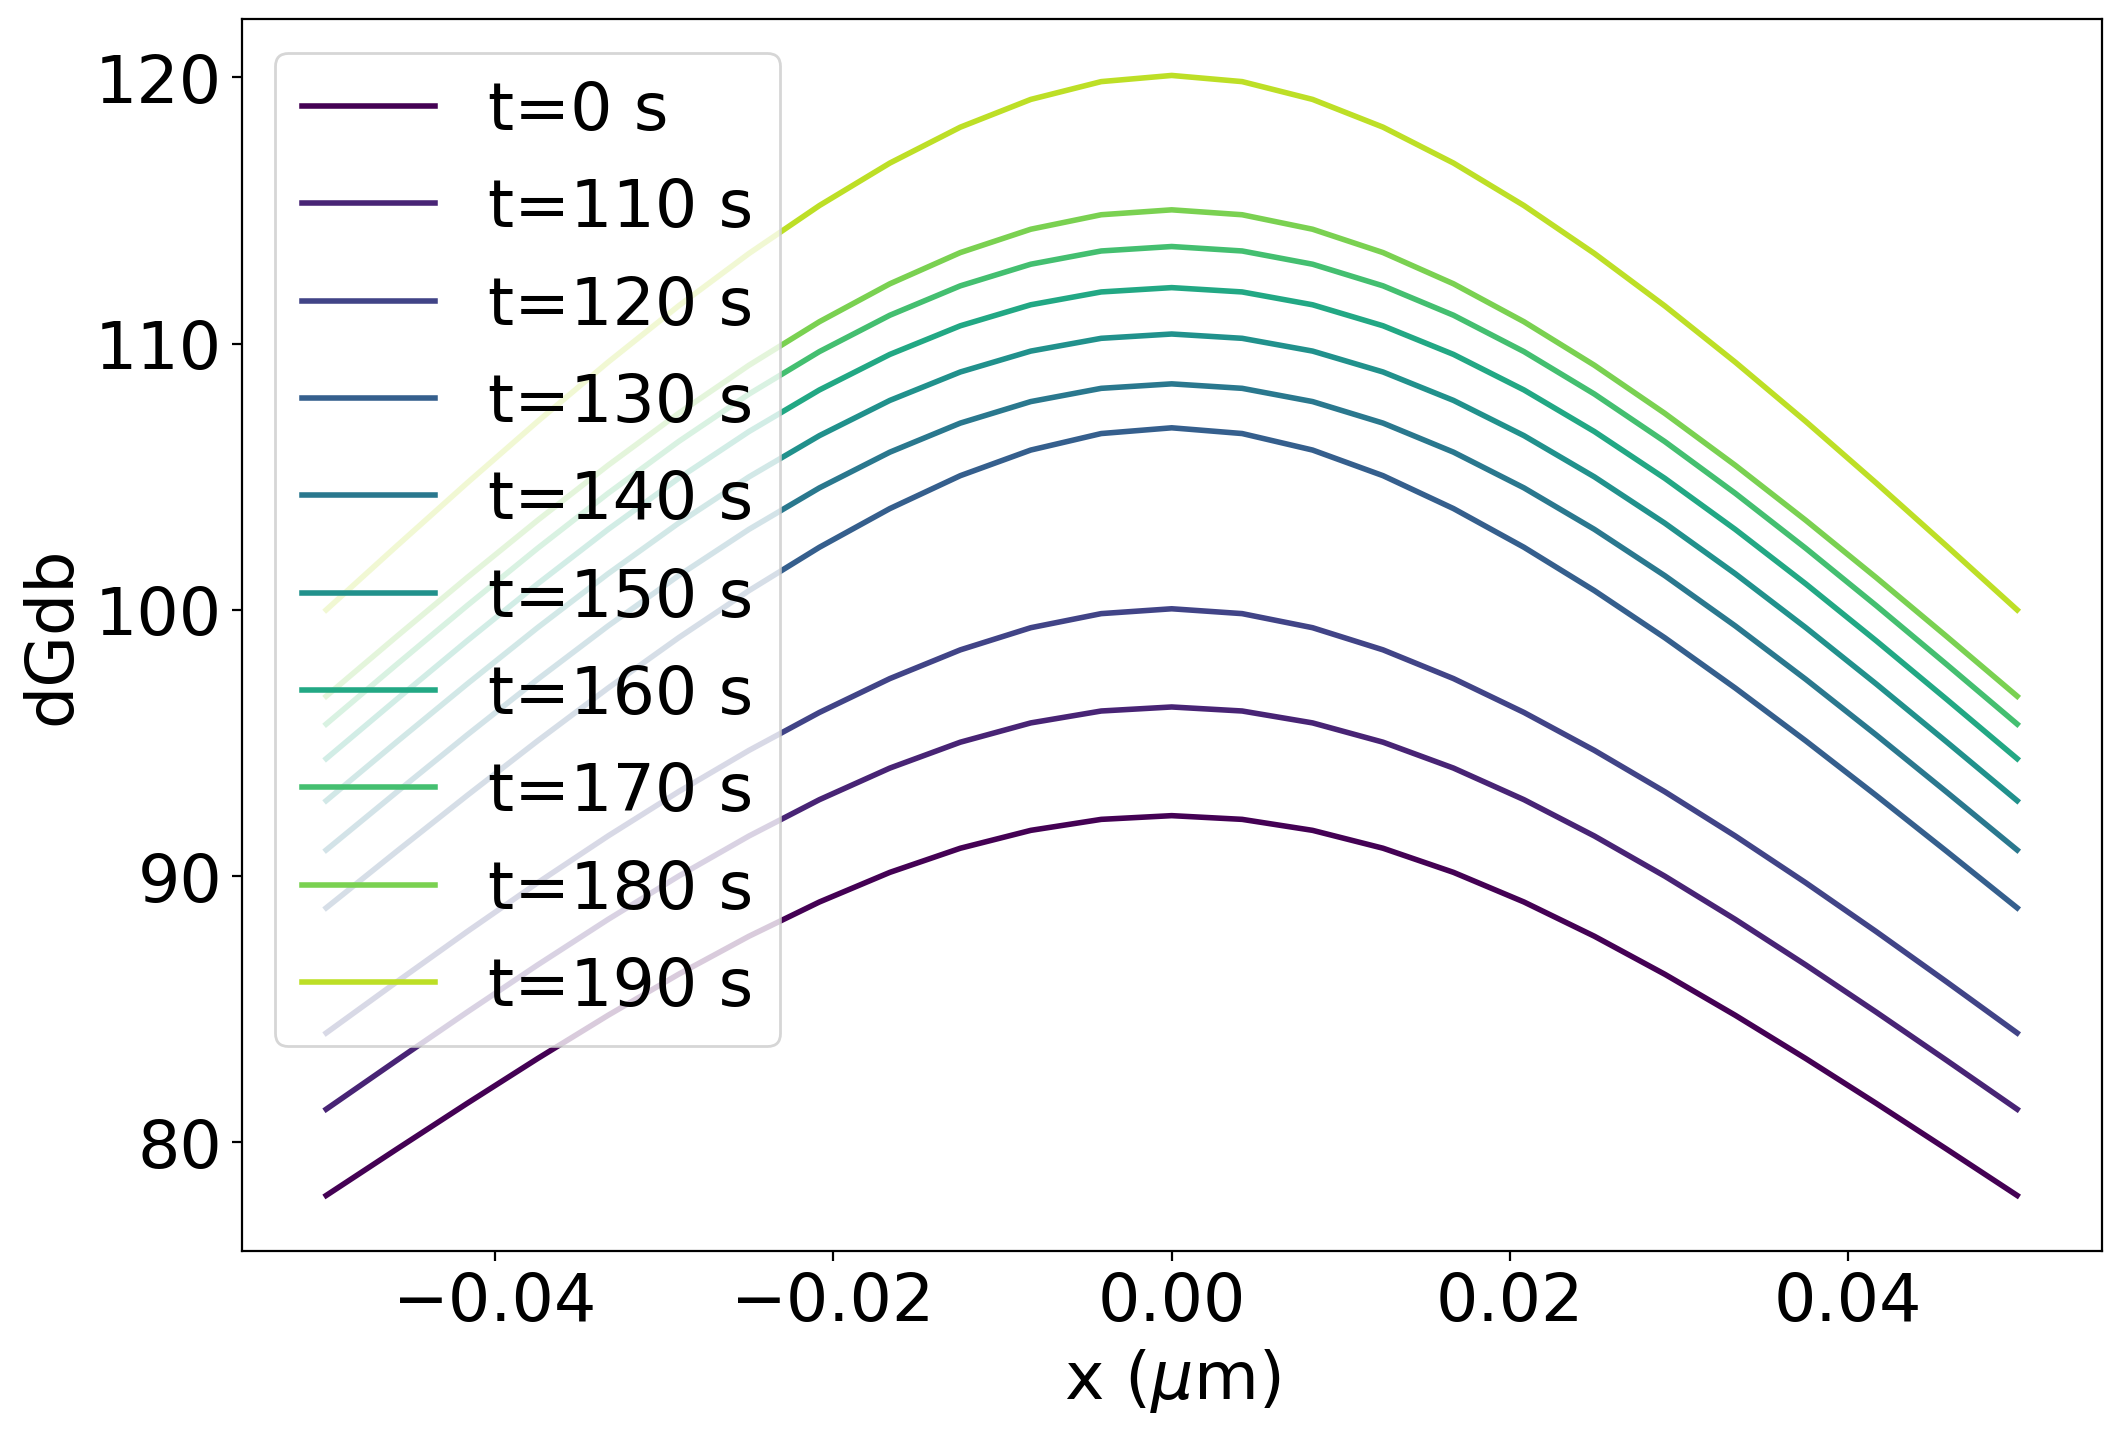

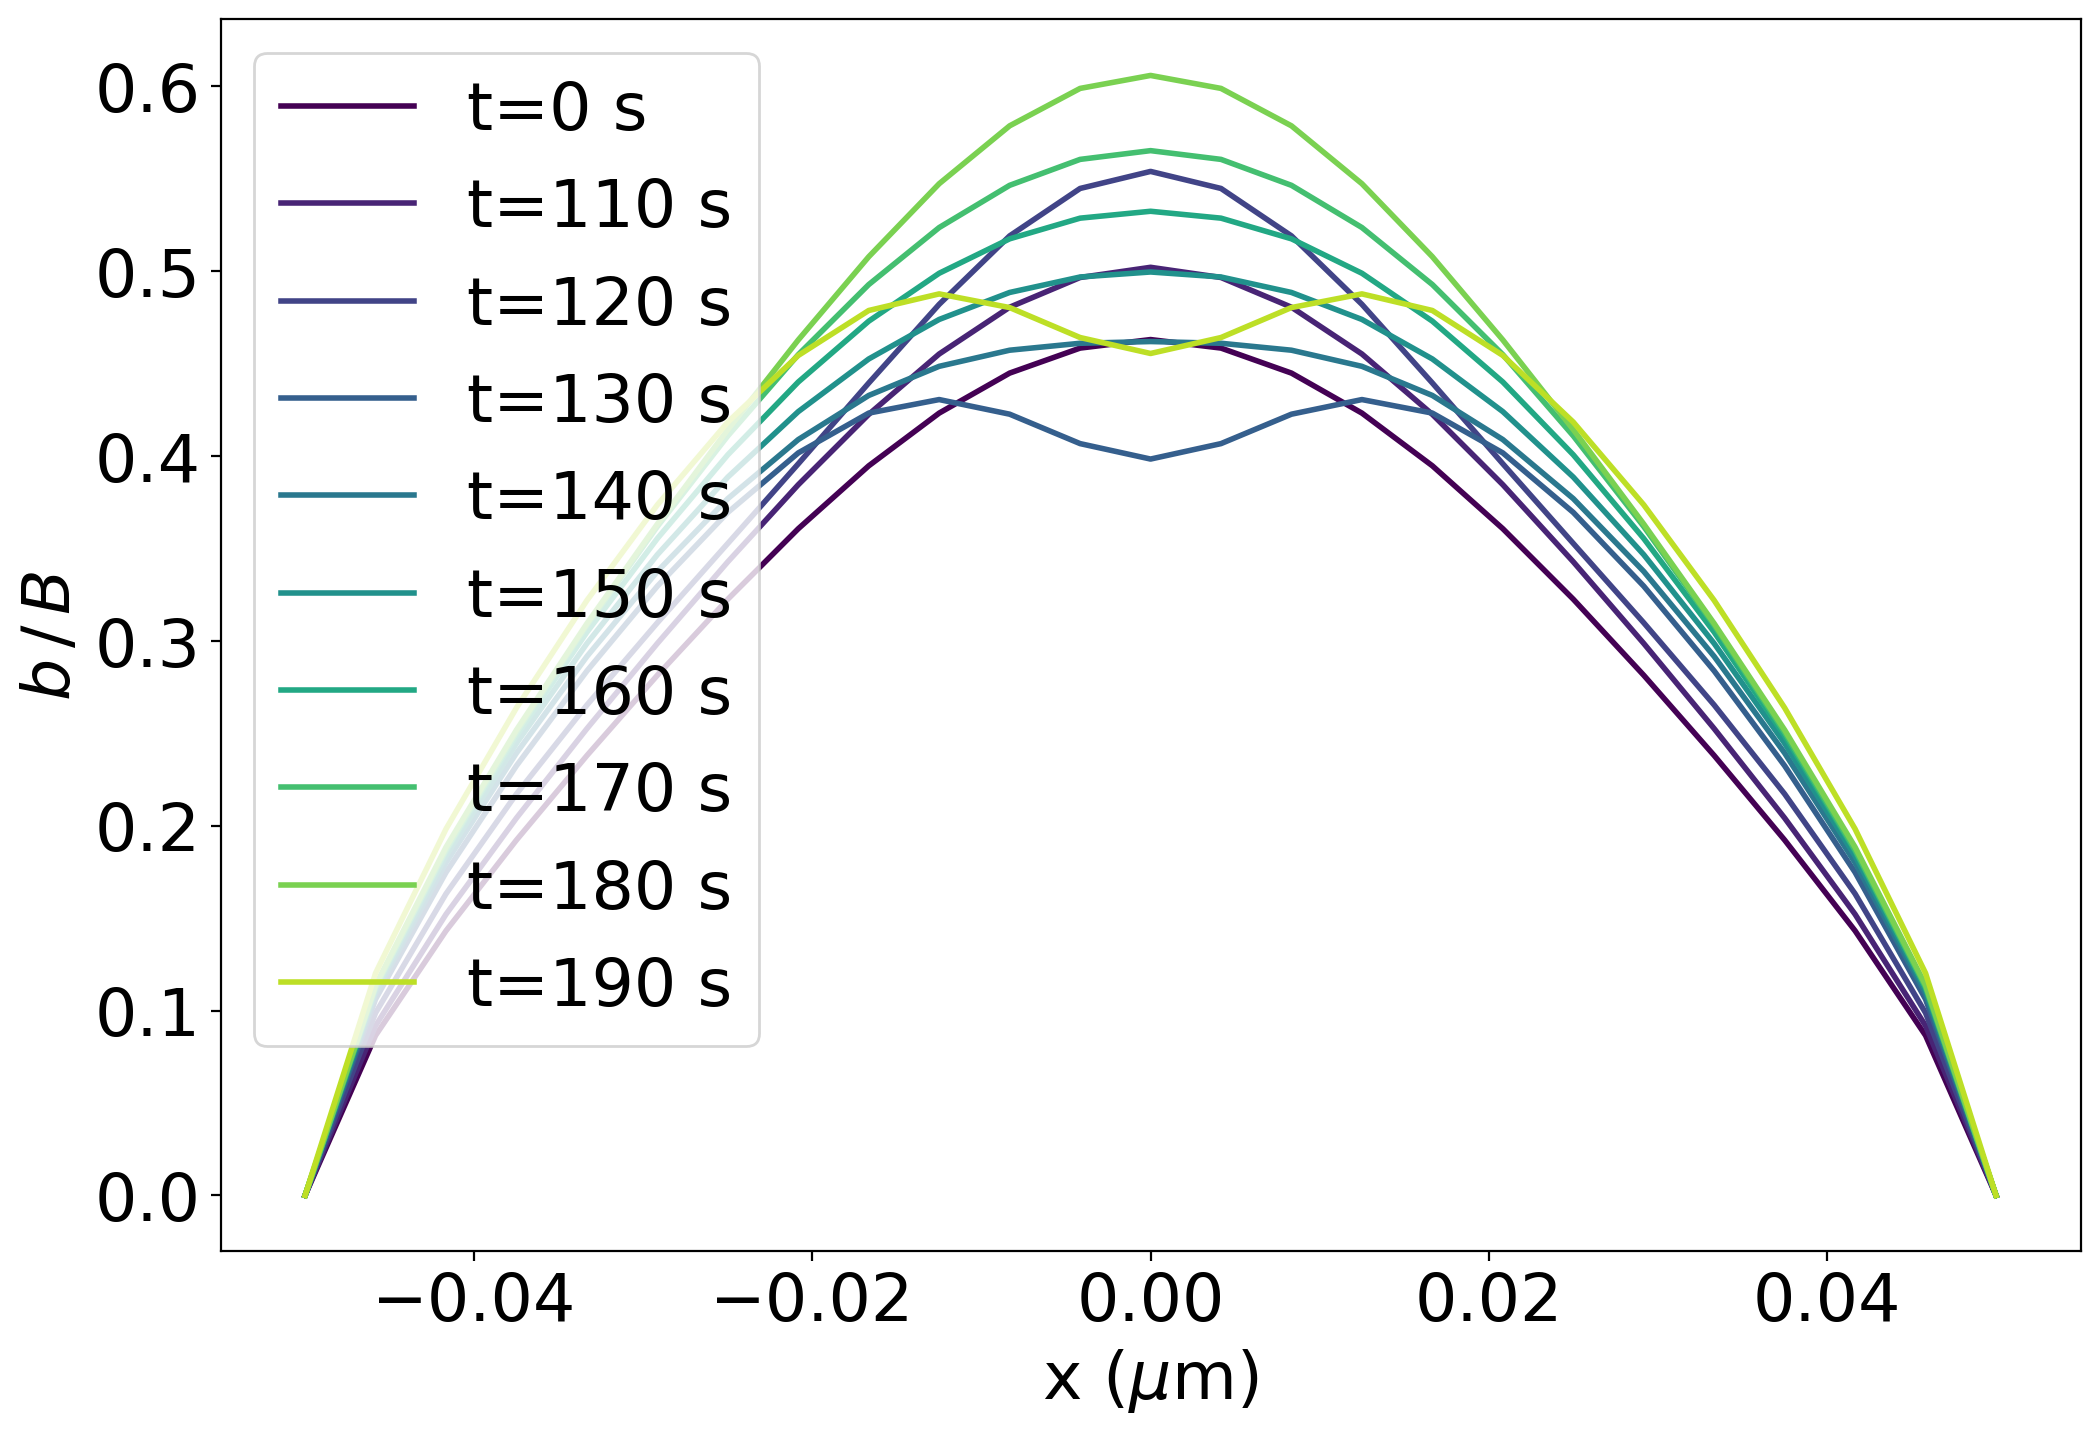

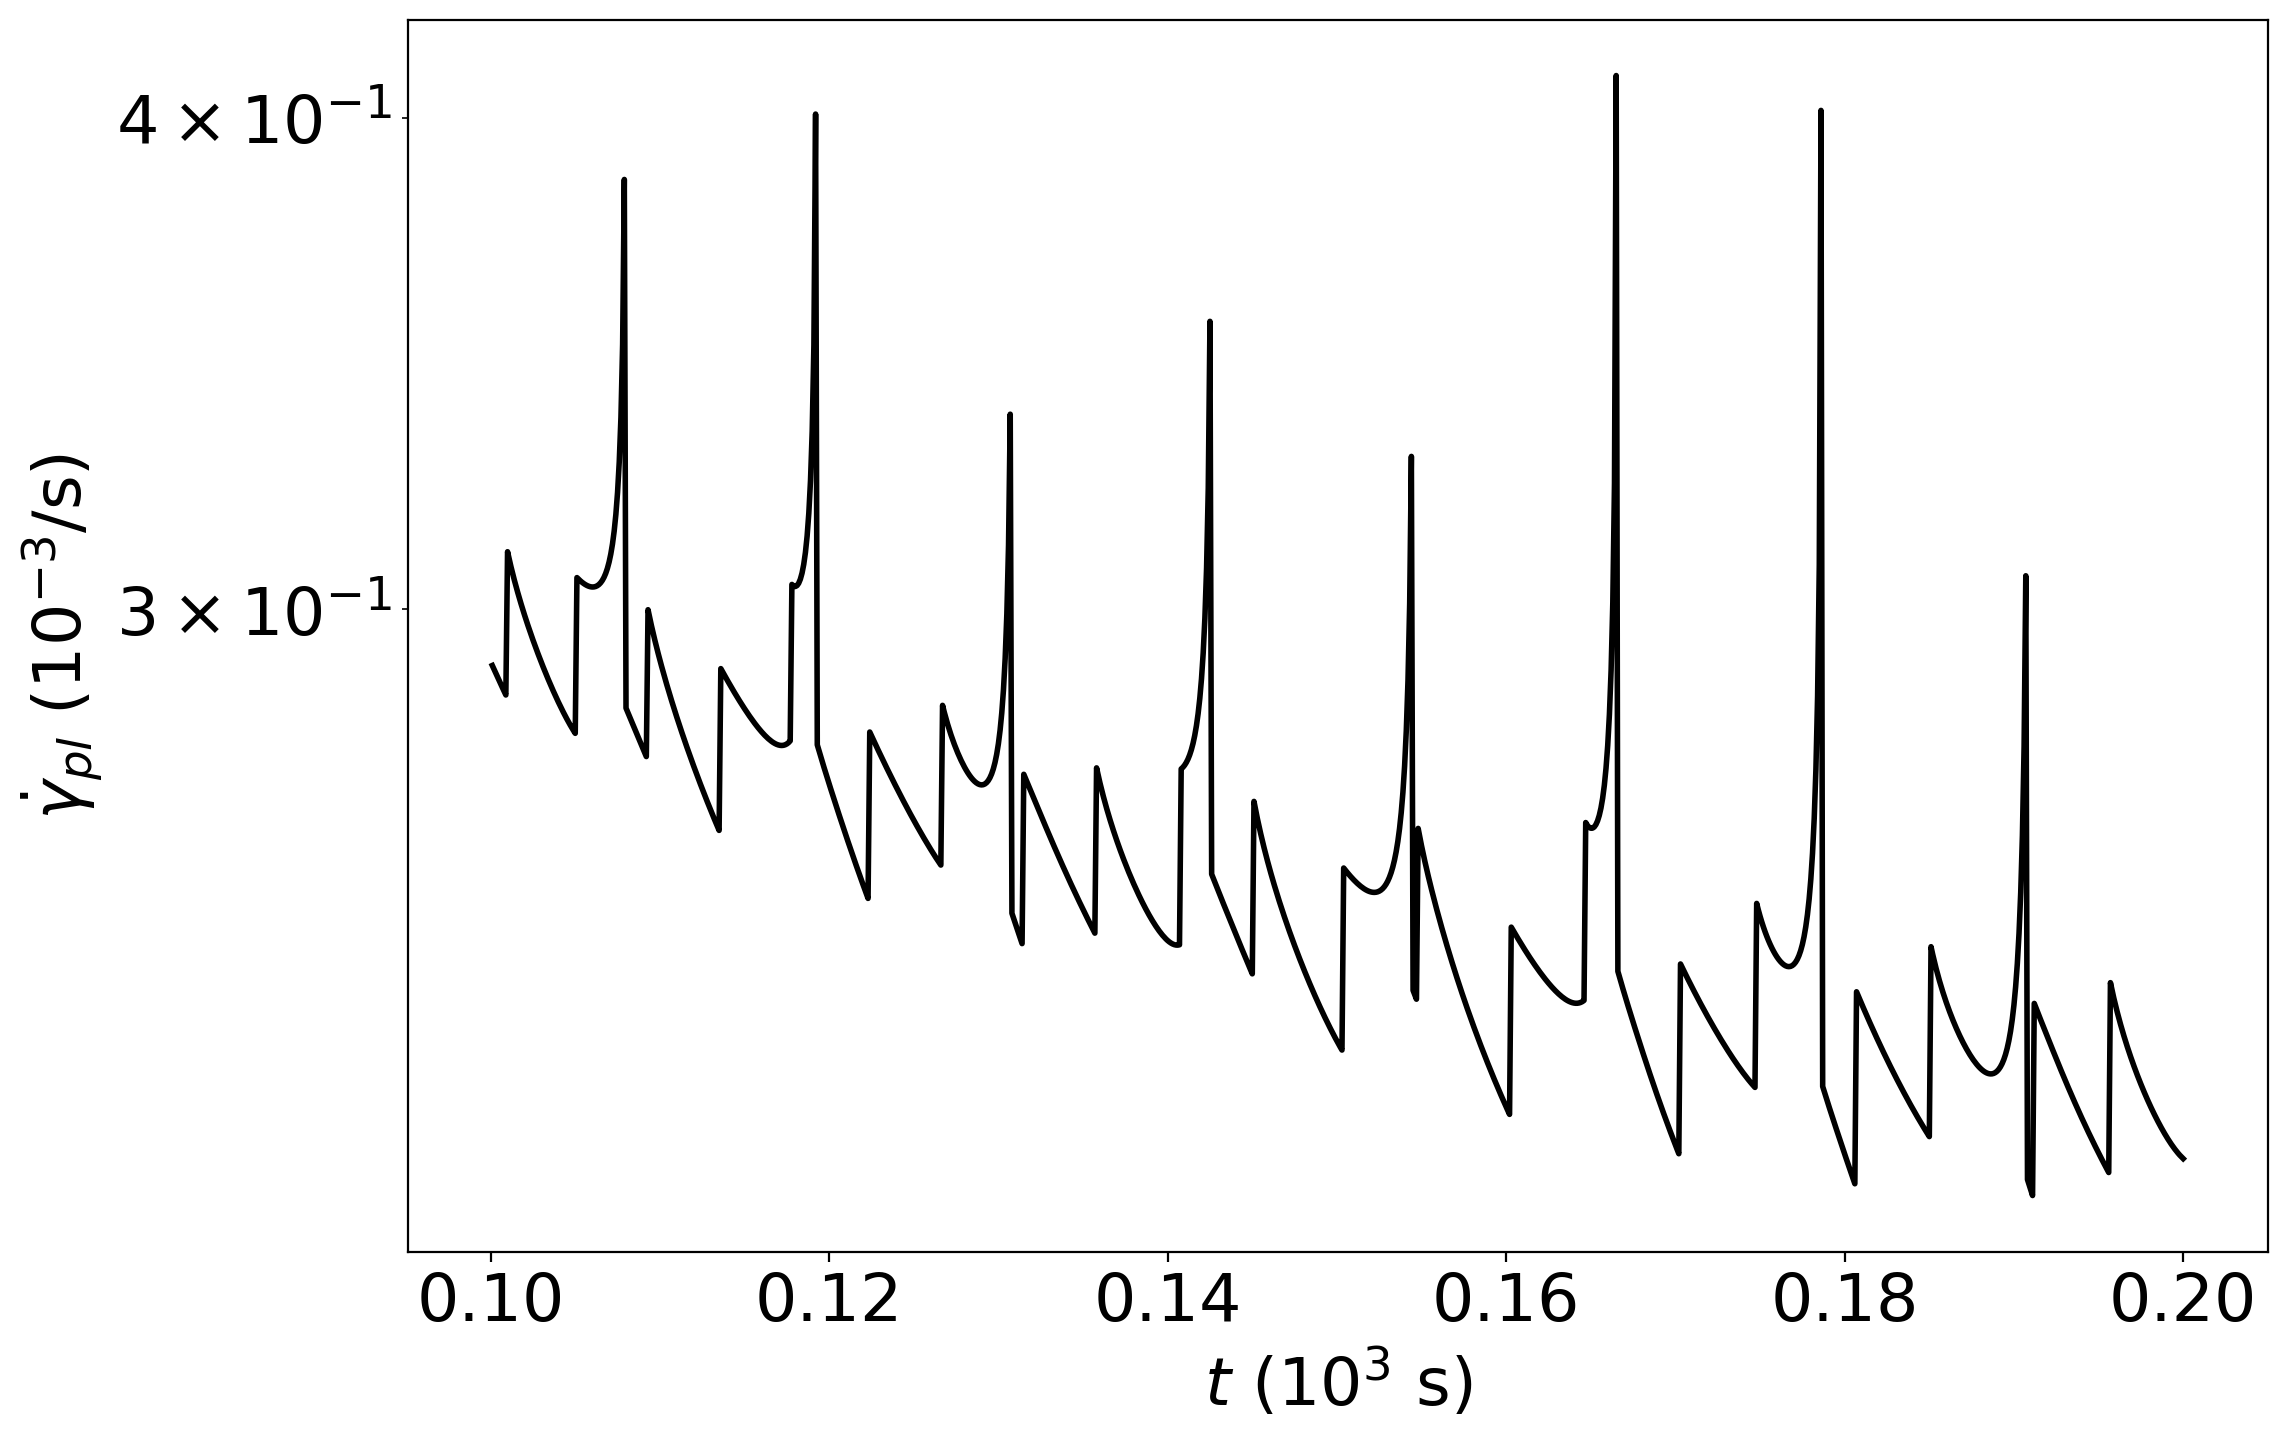

In [6]:
# Restart gbdd simulation
gb_r = dd.GB_dislocations(temp=temp, tau0=tau0,
                   Ngbn=ngbn, len_gb_seg=lgb, grain_size=gs,
                   tfin=tfin, niter=niter, maxout=maxout,
                   dtmax=dtmax, drag=drag,
                   nu=nu, mu=mu, B=b0,
                   screenout=True)
gb_r.run_sim(pudis=gbdd.pu_dis['position'][gbdd.nout-1, :].copy(),
             vout=gbdd.vout[gbdd.nout-1, :, :].copy(),
             r_time=gbdd.sim_time[gbdd.nout-1],
             nabs=gbdd.nabs
            )
gb_r.save_hdf5(f"gbpre_tau{int(tau0)}_T{int(temp)}_H{int(gs*10)}_L{int(lgb*10)}.h5")
gb_r.plot_time_series( ["n_slip_dis", "n_absorbed", "n_gbdis_eff"])
gb_r.plot_field('dGdb')
gb_r.plot_field("bfield")
gb_r.plot_time_series("plast_slip_rate")

In [ ]:
# read existing data from GDF5 files
for i, fname in enumerate(flist):
    gbdd = dd.GB_dislocations(from_file=path+fname+".h5")
    print(f"Data file with D={gbdd.D2}, delta={gbdd.Dgp}, dtmax={gbdd.dtmax}")
    gbdd.plot_time_series(['timestep', 'n_gbdis_eff'])
    print(f"** Max. time step = {max(gbdd.glob_data['timestep'])}, Median: {np.median(gbdd.glob_data['timestep'])}")
    #gbdd.plot_time_series('max_bdot')
    #gbdd.plot_time_series('plast_slip_rate')
    gbdd.plot_time_series('psr_av')
    #gbdd.plot_field('displacement')
    gbdd.plot_field('bfield')
    nit[i] = gbdd.nout
    gs_list[i] = gbdd.D2
    sim_time[i, 0:gbdd.nout] = gbdd.sim_time
    wl = min(25, int(gbdd.nout * 0.1))
    if wl < 2:
        print(f"Warning window length for savgol filter too small: {wl}; too few output items: {gbdd.nout}")
        psr_av[i, 0:gbdd.nout] = gbdd.glob_data['psr_av']
    else:
        psr_av[i, 0:gbdd.nout-1] = savgol_filter(gbdd.glob_data['psr_av'][:-1], window_length=wl, polyorder=1, deriv=0)
    gplast[i, 0:gbdd.nout] = gbdd.glob_data['plastic_slip']
    psr_list[0, i] = np.mean(gbdd.glob_data['plast_slip_rate'][-100:])
    temp_list[0] = 900.
                          

In [ ]:
plt.rcParams["font.size"] = 20

fig, ax = plt.subplots(figsize=(12, 8), dpi=200)
for i in range(Np):
    plt.plot(sim_time[i, :nit[i]-20]*1.e-6,
             psr_av[i, :nit[i]-20]*1.e9,
             marker="none",
             linestyle="-",
             color=plt.cm.viridis(i / max(1, Np)),
             label=f"D={gs_list[i]}"+r" $\mu$m"
             )
plt.legend(loc="upper right", bbox_to_anchor=(1.3, 1.02))
plt.xlabel(r"$t$ (s)")
plt.ylabel(r"$\dot\gamma_{pl}$ (10$^{-3}$/s)")
#plt.savefig('pu1_conv_gd_ngbn_semilog.pdf', dpi=300, format='pdf')
plt.show()

fig, ax = plt.subplots(figsize=(12, 8), dpi=200)
#xval = 1./np.sqrt(gs_list)
#xlabel = r"$1/\sqrt{H}$ ($\mu$m$^{-1/2}$)"
xval = gs_list
xlabel = r"$H$ ($\mu$m)"
plt.plot(xval, psr_list[0,:]*1.e9,
         color='red',
        label=f"T=900 K")
plt.plot(xval, psr_list[1,:]*1.e9,
         color='orange',
        label=f"T=700 K")
plt.plot(xval, psr_list[2,:]*1.e9,
         color='blue',
        label=f"T=500 K")
plt.xlabel(xlabel)
plt.ylabel(r"$\dot\gamma_{pl}$ (10$^{-3}$/s)")
plt.legend()
plt.show()

In [ ]:
psr_list

In [ ]:
psr0 = np.array([[ 1.33603495e-10,  2.00375364e-10,  2.47692749e-10,
         2.48731915e-10,  2.23303212e-10,  1.11401307e-10],
       [ 2.35187569e-11,  4.04464519e-11,  6.37819978e-11,
         1.30645999e-10,  1.94046861e-10,  0.00000000e+00],
       [-9.34075694e-13,  2.97644063e-14,  2.78368262e-13,
         5.12428036e-11,  1.66057001e-10,  0.00000000e+00]])
err = psr_list/psr0[:, :4] - 1.
print(err)

In [ ]:
gbdd.plot_pile_up()
gbdd.plot_time_series('n_slip_dis')

In [ ]:
it = 500
plt.rcParams["font.size"] = 12
sp_ang = 0.5*np.pi
C = gbdd.mu*gbdd.B/(2*np.pi*(1.-gbdd.nu))   # Constant for dislocation stress field
hh = gbdd.pu_dis['position'][it, :]
ind = np.nonzero(hh)[0]
npu = len(ind)
assert npu == gbdd.glob_data['n_slip_dis'][it]
ngbn = gbdd.Ngbn
Nc = int((ngbn+1)/2) - 1
gbdx = gbdd.Dgp/(ngbn-1)
ndis = npu + ngbn
xp = np.zeros(ndis)
yp = np.zeros(ndis)
by = np.ones(ndis)
yp[0:npu] = hh[ind]  # positions of pile-up dislocations stored in first section of array, GB is at y=0
xp[0:npu] = np.ones(npu)*gbdd.Dgp*0.5  # x-positions of pile-up dislocations
xp[npu:] = gbdd.gb_node_pos + gbdd.Dgp*0.5
by[npu:] = gbdd.field_data['bfield'][it, :]  #np.zeros(ngbn) #
print(f"Number of dislocations: {npu}, Simulation time: {gbdd.sim_time[it]*1.e-6}")

#define different dislocations in box
# initialze object of class Dislocations
dsl = dd.Dislocations(ndis, npu, sp_ang, C, gbdd.B,
                      xpos=xp, ypos=yp, LX=gbdd.Dgp, LY=gbdd.D2,  #LX=50000, LY=50000, #
                      bc="fixed")
dsl.by = by
plot_stress_bfield(file=f"sigpu_tau{int(gbdd.tau0)}_T{int(gbdd.temp)}_D{int(gbdd.D2*10)}_L{int(gbdd.Dgp*10)}.pdf", cutoff=200)


In [ ]:

gbdd.Dgp